In [1]:
!pip install -q remotezip huggingface_hub requests pandas numpy matplotlib seaborn pillow opencv-python-headless tqdm scikit-image


In [2]:
import os
import re
import io
import gc
import time
import tarfile
import random
import requests
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from PIL import Image
from pathlib import Path
from collections import Counter, defaultdict
from remotezip import RemoteZip
from tqdm.auto import tqdm
from IPython.display import display

random.seed(42)
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
BASE_DIR = Path("/content/drive/MyDrive/Cityscapes_EDA")

RESULT_DIR = BASE_DIR / "results"

CSV_DIR = RESULT_DIR / "csv"
GRAPH_DIR = RESULT_DIR / "graphs"
REPORT_DIR = RESULT_DIR / "reports"

for folder in [CSV_DIR, GRAPH_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Output directories created.")

Output directories created.


In [6]:
HF_REPO = "AaronCIH/Segmentation"

ACDC_RGB_URL = (
    "https://huggingface.co/datasets/"
    + HF_REPO
    + "/resolve/main/ACDC/rgb_anon_trainvaltest.zip"
)

ACDC_GT_URL = (
    "https://huggingface.co/datasets/"
    + HF_REPO
    + "/resolve/main/ACDC/gt_trainval.zip"
)

CITYSCAPES_C_URL = (
    "https://huggingface.co/datasets/"
    + HF_REPO
    + "/resolve/main/Cityscape-C.tar.gz"
)

# Number of ACDC fog images to analyse
MAX_ACDC_IMAGES = 120

# Number of Cityscapes-C images to process in the initial sample
MAX_CITYC_IMAGES = 500

# Maximum images retained per inferred corruption/severity group
MAX_PER_GROUP = 30

print("Hugging Face dataset URLs configured.")


Hugging Face dataset URLs configured.


In [7]:
print("Connecting to ACDC RGB archive...")

try:
    acdc_rgb_zip = RemoteZip(ACDC_RGB_URL)

    print("RGB archive connected successfully.")

    rgb_files = acdc_rgb_zip.namelist()

    fog_rgb_files = [
        f for f in rgb_files
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
        and "/fog/" in ("/" + f.lower())
        and ("/train/" in ("/" + f.lower())
             or "/val/" in ("/" + f.lower()))
    ]

    print("Total archive entries:", len(rgb_files))
    print("Fog image files found:", len(fog_rgb_files))

    print("\nExample fog image paths:")
    for f in fog_rgb_files[:10]:
        print(f)

except Exception as e:
    print("Could not access the remote RGB ZIP.")
    print("Error:", str(e))
    raise

Connecting to ACDC RGB archive...
RGB archive connected successfully.
Total archive entries: 8225
Fog image files found: 500

Example fog image paths:
rgb_anon/fog/val/GP010476/GP010476_frame_000026_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000255_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000131_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000078_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000073_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000063_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000137_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000242_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000022_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000120_rgb_anon.png


In [8]:
print("Connecting to ACDC annotation archive...")

try:
    acdc_gt_zip = RemoteZip(ACDC_GT_URL)

    gt_files = acdc_gt_zip.namelist()

    fog_gt_files = [
        f for f in gt_files
        if f.lower().endswith(".png")
        and "/fog/" in ("/" + f.lower())
    ]

    print("Total annotation archive entries:", len(gt_files))
    print("Fog annotation files found:", len(fog_gt_files))

    print("\nExample annotation paths:")
    for f in fog_gt_files[:10]:
        print(f)

except Exception as e:
    print("Could not access the remote GT ZIP.")
    print("Error:", str(e))
    raise

Connecting to ACDC annotation archive...
Total annotation archive entries: 10032
Fog annotation files found: 2500

Example annotation paths:
gt/fog/train/GOPR0475/GOPR0475_frame_000041_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000049_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000096_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000116_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000122_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000128_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000135_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000148_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000154_gt_labelIds.png
gt/fog/train/GOPR0475/GOPR0475_frame_000161_gt_labelIds.png


In [9]:
# Correct ACDC filename matching

# Define these helpers before they are used below.
def get_split(path):
    parts = path.lower().replace("\\", "/").split("/")
    for split in ["train", "val", "test"]:
        if split in parts:
            return split
    return "unknown"

def get_sequence(path):
    return Path(path).parent.name


def get_image_key(filename):

    name = Path(filename).name

    suffixes = [
        "_rgb_anon.png",
        "_gt_labelIds.png",
        "_gt_labelTrainIds.png",
        "_gt_labelColor.png",
        "_gt_invIds.png",
        "_gt_invGray.png"
    ]

    for suffix in suffixes:
        if name.endswith(suffix):
            return name[:-len(suffix)]

    return Path(name).stem


# Build annotation lookup
gt_lookup = defaultdict(list)

for filename in fog_gt_files:

    key = get_image_key(filename)

    gt_lookup[key].append(filename)


# Match RGB images with annotations
matched_acdc = []

for rgb_path in fog_rgb_files:

    key = get_image_key(rgb_path)

    matching_masks = gt_lookup.get(key, [])

    if matching_masks:

        matched_acdc.append({
            "image_path": rgb_path,
            "mask_paths": matching_masks,
            "key": key,
            "split": get_split(rgb_path),
            "sequence": get_sequence(rgb_path)
        })


print("Total fog RGB images:", len(fog_rgb_files))
print("Total fog annotations:", len(fog_gt_files))
print("Images with matching annotations:", len(matched_acdc))
print(
    "Images without matching annotations:",
    len(fog_rgb_files) - len(matched_acdc)
)

print("\nMatching examples:")

for item in matched_acdc[:5]:

    print("\nRGB:", item["image_path"])
    print("GT:", item["mask_paths"])

Total fog RGB images: 500
Total fog annotations: 2500
Images with matching annotations: 500
Images without matching annotations: 0

Matching examples:

RGB: rgb_anon/fog/val/GP010476/GP010476_frame_000026_rgb_anon.png
GT: ['gt/fog/val/GP010476/GP010476_frame_000026_gt_labelIds.png', 'gt/fog/val/GP010476/GP010476_frame_000026_gt_labelTrainIds.png', 'gt/fog/val/GP010476/GP010476_frame_000026_gt_labelColor.png', 'gt/fog/val/GP010476/GP010476_frame_000026_gt_invGray.png', 'gt/fog/val/GP010476/GP010476_frame_000026_gt_invIds.png']

RGB: rgb_anon/fog/val/GP010476/GP010476_frame_000255_rgb_anon.png
GT: ['gt/fog/val/GP010476/GP010476_frame_000255_gt_labelIds.png', 'gt/fog/val/GP010476/GP010476_frame_000255_gt_labelTrainIds.png', 'gt/fog/val/GP010476/GP010476_frame_000255_gt_labelColor.png', 'gt/fog/val/GP010476/GP010476_frame_000255_gt_invGray.png', 'gt/fog/val/GP010476/GP010476_frame_000255_gt_invIds.png']

RGB: rgb_anon/fog/val/GP010476/GP010476_frame_000131_rgb_anon.png
GT: ['gt/fog/val/GP0

In [10]:
print("=" * 70)
print("ACDC ARCHIVE STRUCTURE DIAGNOSTIC")
print("=" * 70)

print("\n1. RGB archive: first 15 paths")
for f in fog_rgb_files[:15]:
    print(f)

print("\n2. Annotation archive: first 15 fog paths")
for f in fog_gt_files[:15]:
    print(f)

print("\n3. RGB filenames only")
for f in fog_rgb_files[:10]:
    print(Path(f).name)

print("\n4. Annotation filenames only")
for f in fog_gt_files[:10]:
    print(Path(f).name)

print("\n5. Annotation filename suffix counts")

suffix_counts = Counter(
    Path(f).name.split("_")[-1]
    for f in fog_gt_files
)

print(suffix_counts.most_common(20))

print("\n6. Archive folder names")

print("RGB folders:")
print(sorted(set("/".join(f.split("/")[:-1])
                 for f in fog_rgb_files[:30])))

print("\nGT folders:")
print(sorted(set("/".join(f.split("/")[:-1])
                 for f in fog_gt_files[:30])))

ACDC ARCHIVE STRUCTURE DIAGNOSTIC

1. RGB archive: first 15 paths
rgb_anon/fog/val/GP010476/GP010476_frame_000026_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000255_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000131_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000078_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000073_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000063_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000137_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000242_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000022_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000120_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000147_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000010_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000006_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000125_rgb_anon.png
rgb_anon/fog/val/GP010476/GP010476_frame_000018_rgb_anon.png

2. Annotation arch

In [11]:
from collections import Counter

def get_split(path):
    parts = path.lower().split("/")
    for split in ["train", "val", "test"]:
        if split in parts:
            return split
    return "unknown"


def get_sequence(path):
    return Path(path).parent.name


print("========== RGB SPLIT COUNTS ==========")

rgb_splits = Counter(get_split(f) for f in fog_rgb_files)
print(rgb_splits)

print("\n========== GT SPLIT COUNTS ==========")

gt_splits = Counter(get_split(f) for f in fog_gt_files)
print(gt_splits)


print("\n========== RGB SEQUENCES ==========")

rgb_sequences = Counter(
    get_sequence(f) for f in fog_rgb_files
)

print(rgb_sequences)


print("\n========== GT SEQUENCES ==========")

gt_sequences = Counter(
    get_sequence(f) for f in fog_gt_files
)

print(gt_sequences)


print("\n========== RGB AND GT SEQUENCE OVERLAP ==========")

print(set(rgb_sequences.keys()) & set(gt_sequences.keys()))


print("\n========== RGB TRAIN EXAMPLES ==========")

for f in fog_rgb_files:
    if get_split(f) == "train":
        print(f)
        if sum(1 for x in fog_rgb_files[:fog_rgb_files.index(f)+1]
               if get_split(x) == "train") >= 5:
            break


print("\n========== RGB VAL EXAMPLES ==========")

for f in fog_rgb_files:
    if get_split(f) == "val":
        print(f)
        if sum(1 for x in fog_rgb_files[:fog_rgb_files.index(f)+1]
               if get_split(x) == "val") >= 5:
            break

========== RGB SPLIT COUNTS ==========
Counter({'train': 400, 'val': 100})

========== GT SPLIT COUNTS ==========
Counter({'train': 2000, 'val': 500})

========== RGB SEQUENCES ==========
Counter({'GOPR0477': 103, 'GOPR0476': 101, 'GP010477': 61, 'GP020478': 50, 'GP010476': 41, 'GOPR0478': 41, 'GP020475': 37, 'GOPR0479': 29, 'GOPR0475': 20, 'GP010475': 10, 'GOPR0480': 7})

========== GT SEQUENCES ==========
Counter({'GOPR0477': 515, 'GOPR0476': 505, 'GP010477': 305, 'GP020478': 250, 'GOPR0478': 205, 'GP010476': 205, 'GP020475': 185, 'GOPR0479': 145, 'GOPR0475': 100, 'GP010475': 50, 'GOPR0480': 35})

========== RGB AND GT SEQUENCE OVERLAP ==========
{'GOPR0480', 'GOPR0479', 'GOPR0478', 'GP010475', 'GP020478', 'GOPR0477', 'GOPR0476', 'GP010476', 'GOPR0475', 'GP020475', 'GP010477'}

========== RGB TRAIN EXAMPLES ==========
rgb_anon/fog/train/GP020478/GP020478_frame_000178_rgb_anon.png
rgb_anon/fog/train/GP020478/GP020478_frame_000314_rgb_anon.png
rgb_anon/fog/train/GP020478/GP020478_frame

In [12]:
if len(matched_acdc) == 0:
    raise ValueError("No matching ACDC images found.")

sample_count = min(MAX_ACDC_IMAGES, len(matched_acdc))

acdc_sample = random.sample(
    matched_acdc,
    sample_count
)

print("Selected ACDC fog images:", len(acdc_sample))

print("\nSplit distribution:")

print(
    pd.Series(
        [item["split"] for item in acdc_sample]
    ).value_counts()
)

Selected ACDC fog images: 120

Split distribution:
train    96
val      24
Name: count, dtype: int64


In [13]:
def calculate_entropy(gray):

    hist = cv2.calcHist(
        [gray],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten()

    probabilities = hist / hist.sum()
    probabilities = probabilities[probabilities > 0]

    return -np.sum(probabilities * np.log2(probabilities))


def analyse_image(image_bytes):

    image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

    img = np.array(image)

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2GRAY
    )

    brightness = np.mean(gray)
    contrast = np.std(gray)

    blur = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    entropy = calculate_entropy(gray)

    return {
        "width": image.width,
        "height": image.height,
        "brightness": brightness,
        "contrast": contrast,
        "blur_score": blur,
        "entropy": entropy,
        "file_size_kb": len(image_bytes) / 1024
    }

In [14]:
acdc_records = []
acdc_previews = []

for item in tqdm(acdc_sample):

    try:
        image_bytes = acdc_rgb_zip.read(item["image_path"])

        stats = analyse_image(image_bytes)

        record = {
            "filename": Path(item["image_path"]).name,
            "split": (
                "train" if "/train/" in item["image_path"].lower()
                else "val"
            ),
            **stats
        }

        acdc_records.append(record)

        if len(acdc_previews) < 6:
            preview = Image.open(
                io.BytesIO(image_bytes)
            ).convert("RGB")

            acdc_previews.append({
                "filename": record["filename"],
                "image": preview.copy()
            })

        del image_bytes

    except Exception as e:
        print("Skipping:", item["image_path"], str(e))


acdc_df = pd.DataFrame(acdc_records)

print("ACDC analysis completed.")
display(acdc_df.head())

print("\nDataset shape:", acdc_df.shape)

  0%|          | 0/120 [00:00<?, ?it/s]

ACDC analysis completed.


,filename,split,width,height,brightness,contrast,blur_score,entropy,file_size_kb
0,GOPR0477_frame_000756_rgb_anon.png,train,1920,1080,131.367083,62.247558,95.261711,7.278248,1218.619141
1,GOPR0476_frame_000921_rgb_anon.png,val,1920,1080,139.547808,62.714792,90.611107,7.297275,1274.296875
2,GP010476_frame_000006_rgb_anon.png,val,1920,1080,133.257877,60.498976,74.391833,7.039037,1216.937500
3,GOPR0480_frame_000072_rgb_anon.png,train,1920,1080,112.454598,66.503536,213.169715,7.483119,1544.737305
4,GP020478_frame_000329_rgb_anon.png,train,1920,1080,120.257494,77.053551,118.551596,7.516327,1621.110352



Dataset shape: (120, 9)


In [15]:
mask_records = []
class_pixel_counts = Counter()

for item in tqdm(acdc_sample):

    try:
        image_key = item["key"]

        candidates = item["mask_paths"]

        # Prefer train IDs when available
        preferred = [
            f for f in candidates
            if "_gt_labelTrainIds.png" in f
        ]

        if not preferred:
            preferred = [
                f for f in candidates
                if "_gt_labelIds.png" in f
            ]

        if not preferred:
            continue

        mask_path = preferred[0]

        mask_bytes = acdc_gt_zip.read(mask_path)

        mask = np.array(
            Image.open(io.BytesIO(mask_bytes))
        )

        unique_values, counts = np.unique(
            mask,
            return_counts=True
        )

        for value, count in zip(unique_values, counts):
            class_pixel_counts[int(value)] += int(count)

        mask_records.append({
            "filename": Path(mask_path).name,
            "width": mask.shape[1],
            "height": mask.shape[0],
            "unique_labels": len(unique_values),
            "total_pixels": mask.size
        })

    except Exception as e:
        print("Mask skipped:", item["key"], str(e))


acdc_mask_df = pd.DataFrame(mask_records)

print("Masks analysed:", len(acdc_mask_df))
display(acdc_mask_df.head())

  0%|          | 0/120 [00:00<?, ?it/s]

Masks analysed: 120


,filename,width,height,unique_labels,total_pixels
0,GOPR0477_frame_000756_gt_labelTrainIds.png,1920,1080,11,2073600
1,GOPR0476_frame_000921_gt_labelTrainIds.png,1920,1080,13,2073600
2,GP010476_frame_000006_gt_labelTrainIds.png,1920,1080,13,2073600
3,GOPR0480_frame_000072_gt_labelTrainIds.png,1920,1080,14,2073600
4,GP020478_frame_000329_gt_labelTrainIds.png,1920,1080,11,2073600


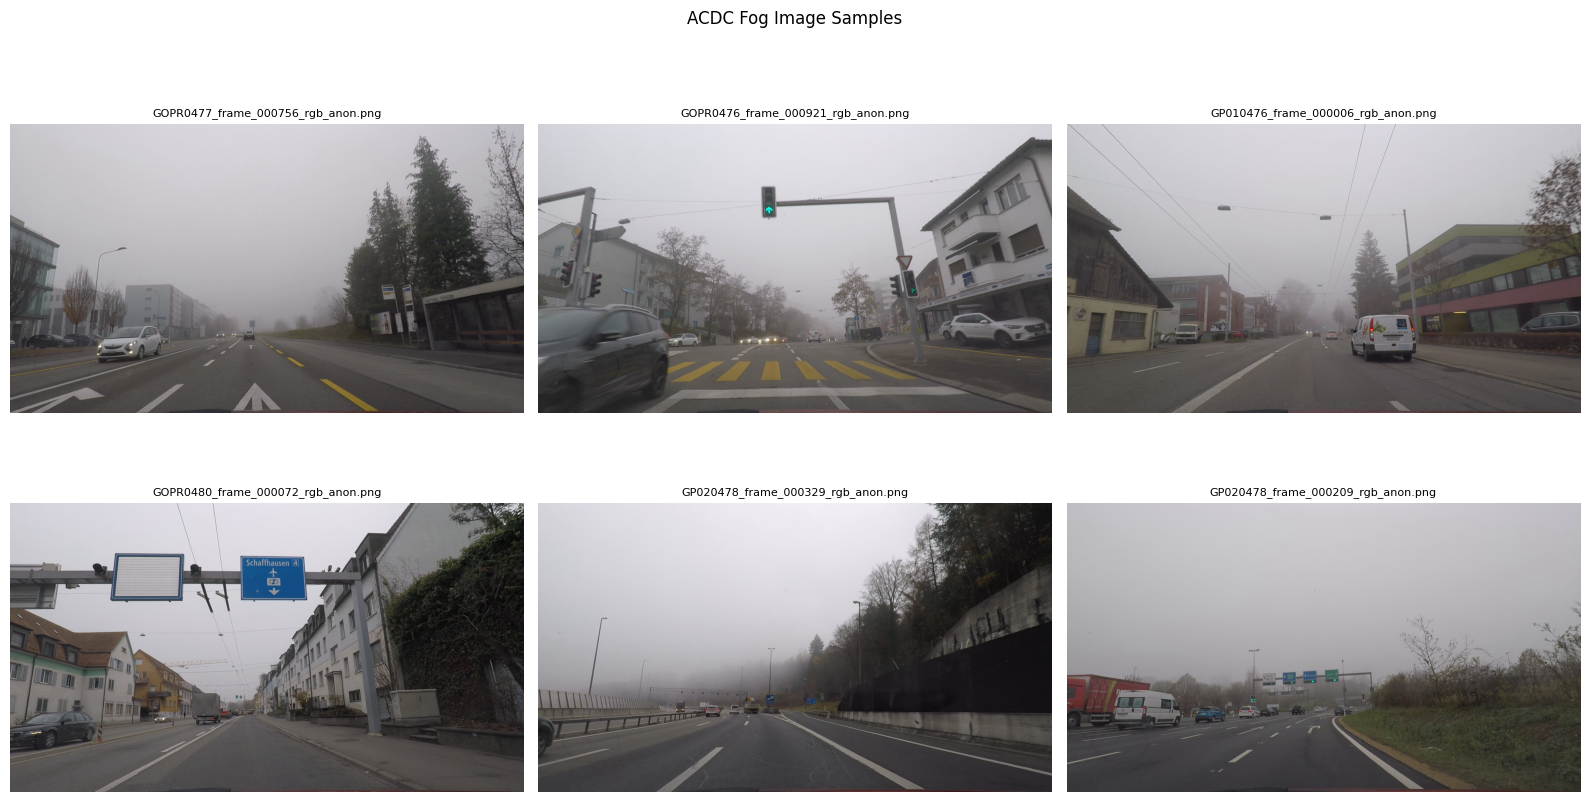

In [16]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for ax, item in zip(axes.flat, acdc_previews):

    ax.imshow(item["image"])
    ax.set_title(item["filename"], fontsize=8)
    ax.axis("off")

plt.suptitle("ACDC Fog Image Samples")
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "ACDC_Fog_Sample_Images.png",
    dpi=300
)

plt.show()

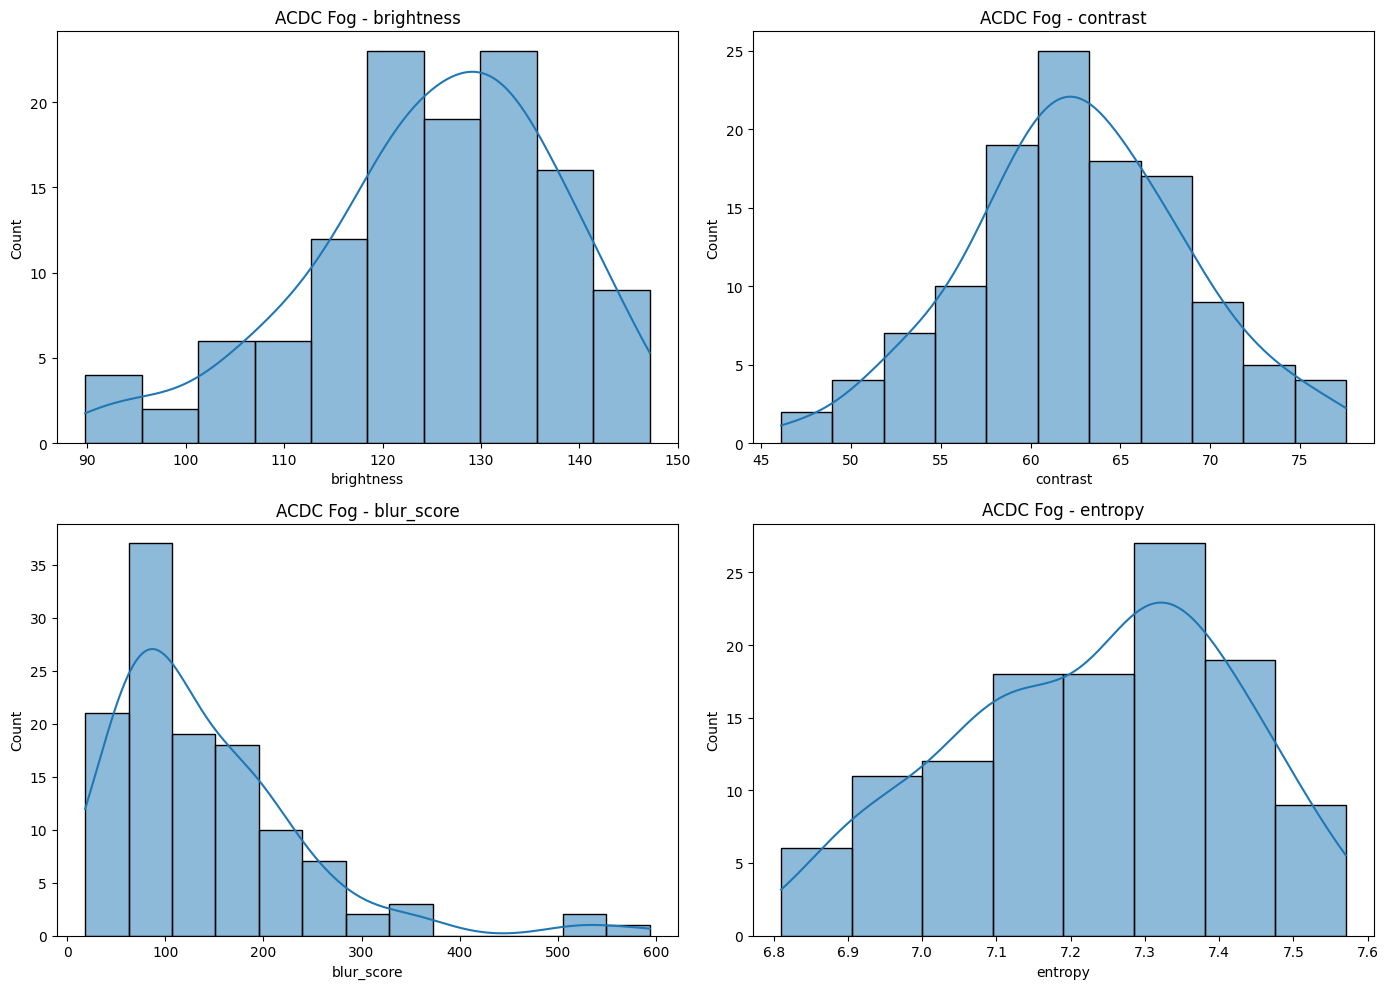

In [17]:
metrics = [
    "brightness",
    "contrast",
    "blur_score",
    "entropy"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for ax, metric in zip(axes.flat, metrics):

    sns.histplot(
        acdc_df[metric],
        kde=True,
        ax=ax
    )

    ax.set_title(f"ACDC Fog - {metric}")

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "ACDC_Fog_Quality_Distributions.png",
    dpi=300
)

plt.show()

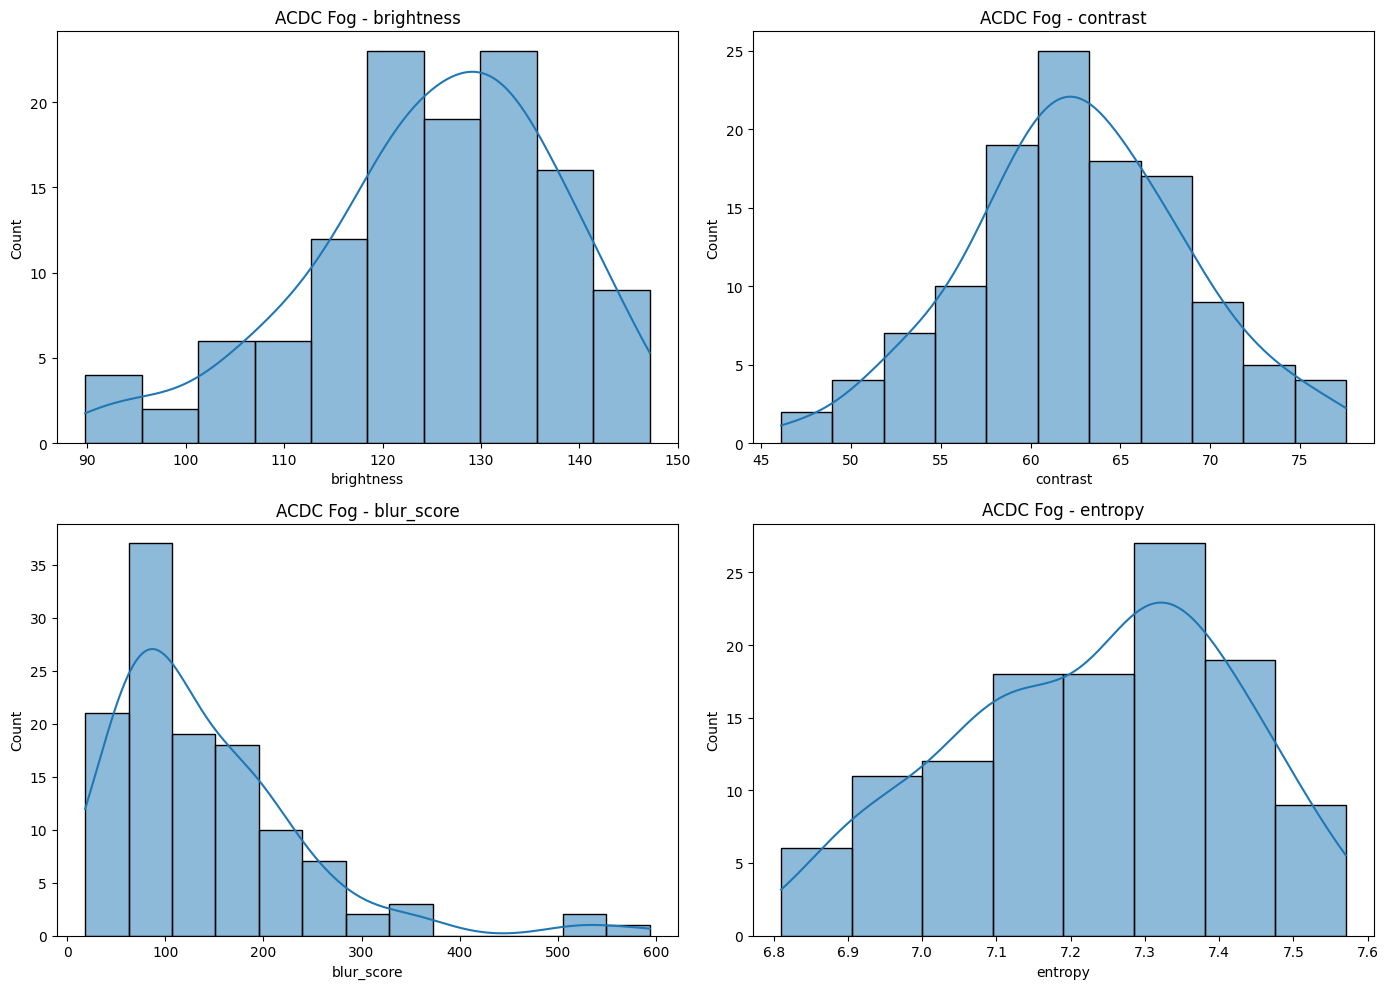

In [18]:
metrics = [
    "brightness",
    "contrast",
    "blur_score",
    "entropy"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for ax, metric in zip(axes.flat, metrics):

    sns.histplot(
        acdc_df[metric],
        kde=True,
        ax=ax
    )

    ax.set_title(f"ACDC Fog - {metric}")

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "ACDC_Fog_Quality_Distributions.png",
    dpi=300
)

plt.show()

In [19]:
acdc_summary = acdc_df[metrics].describe().T

display(acdc_summary)

acdc_summary.to_csv(
    CSV_DIR / "ACDC_Fog_Descriptive_Statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max
brightness,120.0,125.239245,12.498166,89.780328,118.697909,127.485205,133.677596,147.163657
contrast,120.0,62.677983,6.220369,46.111791,58.882135,62.378587,66.623129,77.556280
blur_score,120.0,140.543951,100.177490,18.271399,73.341160,113.228306,189.273241,593.896386
entropy,120.0,7.232034,0.184371,6.810052,7.099040,7.274885,7.357899,7.570597


In [20]:
from collections import Counter
from pathlib import Path
from PIL import Image
import numpy as np
import io
import pandas as pd
from tqdm.auto import tqdm

class_pixel_counts = Counter()

mask_records = []

for item in tqdm(acdc_sample, desc="Processing ACDC masks"):

    try:
        candidates = item["mask_paths"]

        # Prefer semantic train IDs
        preferred = [
            f for f in candidates
            if "_gt_labelTrainIds.png" in f
        ]

        # Fallback to original label IDs
        if not preferred:
            preferred = [
                f for f in candidates
                if "_gt_labelIds.png" in f
            ]

        if not preferred:
            continue

        mask_path = preferred[0]

        mask_bytes = acdc_gt_zip.read(mask_path)

        mask = np.array(
            Image.open(io.BytesIO(mask_bytes))
        )

        unique_values, counts = np.unique(
            mask,
            return_counts=True
        )

        for value, count in zip(unique_values, counts):
            class_pixel_counts[int(value)] += int(count)

        mask_records.append({
            "filename": Path(mask_path).name,
            "width": mask.shape[1],
            "height": mask.shape[0],
            "unique_labels": len(unique_values),
            "total_pixels": mask.size
        })

    except Exception as e:
        print("Error:", item["key"], str(e))


# Create DataFrames
acdc_mask_df = pd.DataFrame(mask_records)

acdc_class_df = pd.DataFrame(
    class_pixel_counts.items(),
    columns=["label_id", "pixel_count"]
).sort_values("label_id")

print("Masks analysed:", len(acdc_mask_df))
print("Unique label IDs:", len(acdc_class_df))

display(acdc_class_df)

Processing ACDC masks:   0%|          | 0/120 [00:00<?, ?it/s]

Masks analysed: 120
Unique label IDs: 20


,label_id,pixel_count
0,0,39208444
1,1,7720847
2,2,23293841
11,3,3135881
12,4,4710904
3,5,2224047
13,6,377018
4,7,852568
5,8,48023913
6,9,5610383


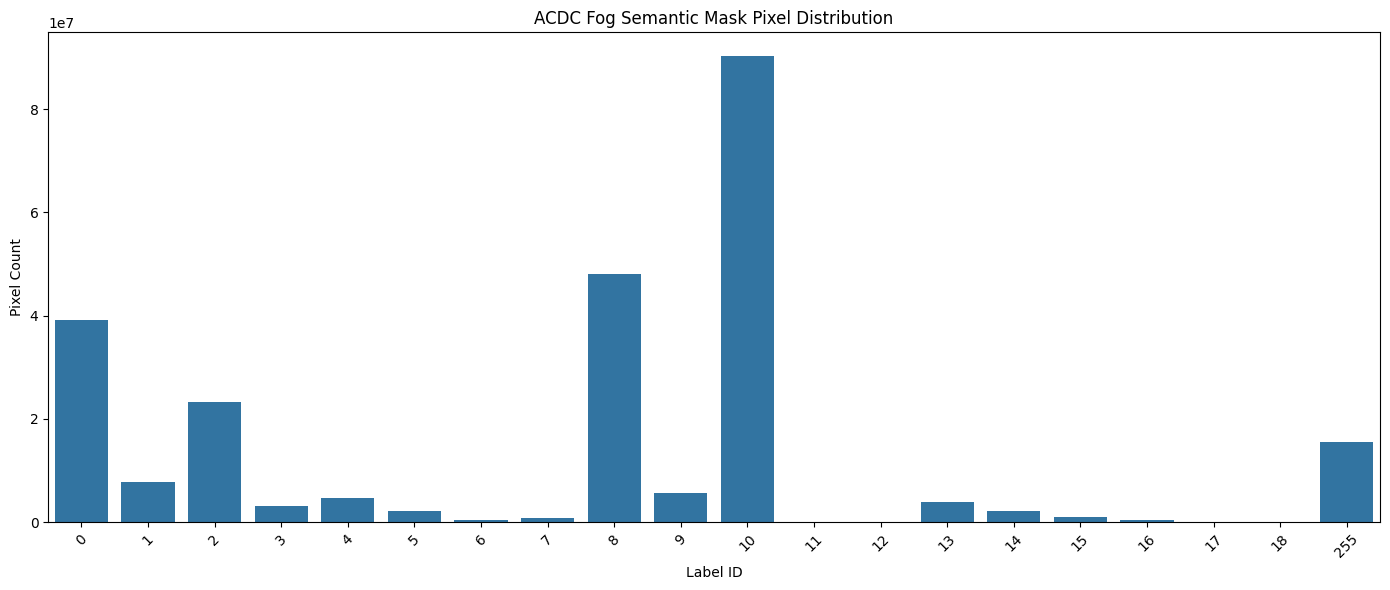

In [21]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=acdc_class_df,
    x="label_id",
    y="pixel_count"
)

plt.title("ACDC Fog Semantic Mask Pixel Distribution")
plt.xlabel("Label ID")
plt.ylabel("Pixel Count")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "ACDC_Fog_Class_Distribution.png",
    dpi=300
)

plt.show()

In [22]:
acdc_class_df.to_csv(
    CSV_DIR / "ACDC_Fog_Class_Pixel_Distribution.csv",
    index=False
)

print("ACDC class distribution saved successfully.")

ACDC class distribution saved successfully.


In [23]:
acdc_summary = acdc_df[metrics].describe().T

display(acdc_summary)

acdc_summary.to_csv(
    CSV_DIR / "ACDC_Fog_Descriptive_Statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max
brightness,120.0,125.239245,12.498166,89.780328,118.697909,127.485205,133.677596,147.163657
contrast,120.0,62.677983,6.220369,46.111791,58.882135,62.378587,66.623129,77.556280
blur_score,120.0,140.543951,100.177490,18.271399,73.341160,113.228306,189.273241,593.896386
entropy,120.0,7.232034,0.184371,6.810052,7.099040,7.274885,7.357899,7.570597


In [24]:
# Number of image entries to process in this run
MAX_CITYC_IMAGES = 500

# Maximum sample size for each inferred group
MAX_PER_GROUP = 30

print("Cityscapes-C streaming configuration ready.")

Cityscapes-C streaming configuration ready.


In [25]:
CORRUPTION_NAMES = [
    "gaussian_noise",
    "shot_noise",
    "impulse_noise",
    "defocus_blur",
    "glass_blur",
    "motion_blur",
    "zoom_blur",
    "snow",
    "frost",
    "fog",
    "brightness",
    "contrast",
    "elastic_transform",
    "pixelate",
    "jpeg_compression",
    "saturate",
    "speckle_noise",
    "gaussian_blur"
]


def infer_corruption_severity(filepath):

    parts = filepath.lower().replace("\\", "/").split("/")

    corruption = "unknown"
    severity = "unknown"

    for part in parts:

        if part in CORRUPTION_NAMES:
            corruption = part

        if part in ["1", "2", "3", "4", "5"]:
            severity = int(part)

        match = re.search(
            r"severity[_-]?([1-5])",
            part
        )

        if match:
            severity = int(match.group(1))

    return corruption, severity

In [26]:
cityc_records = []
cityc_previews = []

group_counts = Counter()

image_extensions = (
    ".png",
    ".jpg",
    ".jpeg"
)

response = requests.get(
    CITYSCAPES_C_URL,
    stream=True,
    timeout=(30, 180)
)

response.raise_for_status()

response.raw.decode_content = True

print("Connected to Cityscapes-C archive.")
print("Beginning streaming analysis...")

processed = 0
skipped = 0

try:

    with tarfile.open(
        fileobj=response.raw,
        mode="r|gz"
    ) as tar:

        for member in tar:

            if not member.isfile():
                continue

            if not member.name.lower().endswith(image_extensions):
                continue

            if processed >= MAX_CITYC_IMAGES:
                break

            corruption, severity = infer_corruption_severity(
                member.name
            )

            group = (corruption, severity)

            if group_counts[group] >= MAX_PER_GROUP:
                skipped += 1
                continue

            file_object = tar.extractfile(member)

            if file_object is None:
                continue

            image_bytes = file_object.read()

            try:

                stats = analyse_image(image_bytes)

                cityc_records.append({
                    "filename": Path(member.name).name,
                    "archive_path": member.name,
                    "corruption": corruption,
                    "severity": severity,
                    **stats
                })

                group_counts[group] += 1
                processed += 1

                if len(cityc_previews) < 6:

                    preview = Image.open(
                        io.BytesIO(image_bytes)
                    ).convert("RGB")

                    cityc_previews.append({
                        "filename": Path(member.name).name,
                        "corruption": corruption,
                        "severity": severity,
                        "image": preview.copy()
                    })

            except Exception as e:
                skipped += 1

            del image_bytes

            if processed % 50 == 0:
                print(
                    f"Processed {processed} images | "
                    f"Groups observed: {len(group_counts)}"
                )

finally:
    response.close()

cityc_df = pd.DataFrame(cityc_records)

print("\nStreaming completed or sample limit reached.")
print("Images analysed:", len(cityc_df))
print("Entries skipped:", skipped)
print("Groups observed:", len(group_counts))

display(cityc_df.head())

Connected to Cityscapes-C archive.
Beginning streaming analysis...
Processed 50 images | Groups observed: 2
Processed 100 images | Groups observed: 4
Processed 150 images | Groups observed: 5
Processed 200 images | Groups observed: 7
Processed 250 images | Groups observed: 9
Processed 300 images | Groups observed: 10
Processed 350 images | Groups observed: 12
Processed 400 images | Groups observed: 14
Processed 450 images | Groups observed: 15
Processed 500 images | Groups observed: 17

Streaming completed or sample limit reached.
Images analysed: 500
Entries skipped: 7520
Groups observed: 17


,filename,archive_path,corruption,severity,width,height,brightness,contrast,blur_score,entropy,file_size_kb
0,frankfurt_000001_055172_leftImg8bit.png,Cityscape-C/pixelate/3/frankfurt/frankfurt_000...,pixelate,3,2048,1024,91.452271,39.619262,152.103850,7.131674,716.631836
1,frankfurt_000001_046272_leftImg8bit.png,Cityscape-C/pixelate/3/frankfurt/frankfurt_000...,pixelate,3,2048,1024,92.024543,68.824191,472.515470,7.233768,804.980469
2,frankfurt_000000_021879_leftImg8bit.png,Cityscape-C/pixelate/3/frankfurt/frankfurt_000...,pixelate,3,2048,1024,95.238591,47.991776,92.670089,6.936742,685.521484
3,frankfurt_000001_012038_leftImg8bit.png,Cityscape-C/pixelate/3/frankfurt/frankfurt_000...,pixelate,3,2048,1024,84.312146,44.107500,184.645251,7.073999,748.867188
4,frankfurt_000001_009058_leftImg8bit.png,Cityscape-C/pixelate/3/frankfurt/frankfurt_000...,pixelate,3,2048,1024,93.955504,56.712571,289.107062,7.242775,692.035156


In [27]:
if len(cityc_df) > 0:

    group_summary = (
        cityc_df
        .groupby(["corruption", "severity"])
        .size()
        .reset_index(name="image_count")
    )

    display(group_summary)

    print("\nCorruption types found:")
    print(cityc_df["corruption"].value_counts())

    print("\nSeverity levels found:")
    print(cityc_df["severity"].value_counts())

else:
    print("No Cityscapes-C images were analysed.")

,corruption,severity,image_count
0,defocus_blur,3,30
1,defocus_blur,5,30
2,fog,3,30
3,fog,5,30
4,glass_blur,3,30
5,glass_blur,5,30
6,motion_blur,3,30
7,motion_blur,5,30
8,pixelate,3,30
9,pixelate,5,30



Corruption types found:
corruption
pixelate         60
motion_blur      60
saturate         60
glass_blur       60
fog              60
zoom_blur        60
defocus_blur     60
snow             60
speckle_noise    20
Name: count, dtype: int64

Severity levels found:
severity
3    260
5    240
Name: count, dtype: int64


In [28]:
cityc_df.to_csv(
    CSV_DIR / "Cityscapes_C_Image_Analysis.csv",
    index=False
)

if len(cityc_df) > 0:

    group_summary.to_csv(
        CSV_DIR / "Cityscapes_C_Group_Summary.csv",
        index=False
    )

print("Cityscapes-C CSV files saved.")

Cityscapes-C CSV files saved.


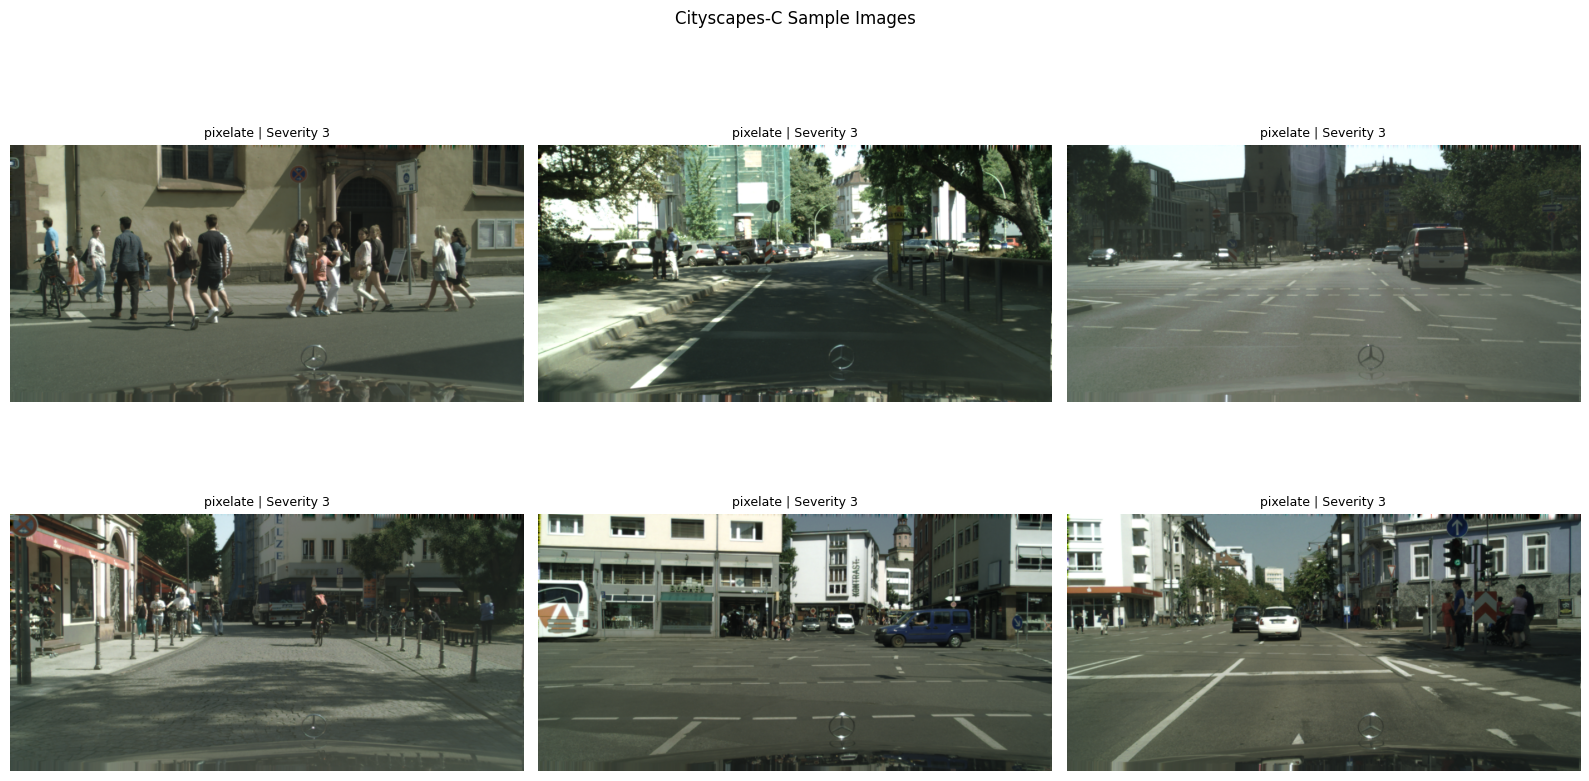

In [29]:
if cityc_previews:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(16, 9)
    )

    for ax, item in zip(axes.flat, cityc_previews):

        ax.imshow(item["image"])

        ax.set_title(
            f"{item['corruption']} | Severity {item['severity']}",
            fontsize=9
        )

        ax.axis("off")

    plt.suptitle("Cityscapes-C Sample Images")
    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / "Cityscapes_C_Sample_Images.png",
        dpi=300
    )

    plt.show()

else:
    print("No preview images available.")

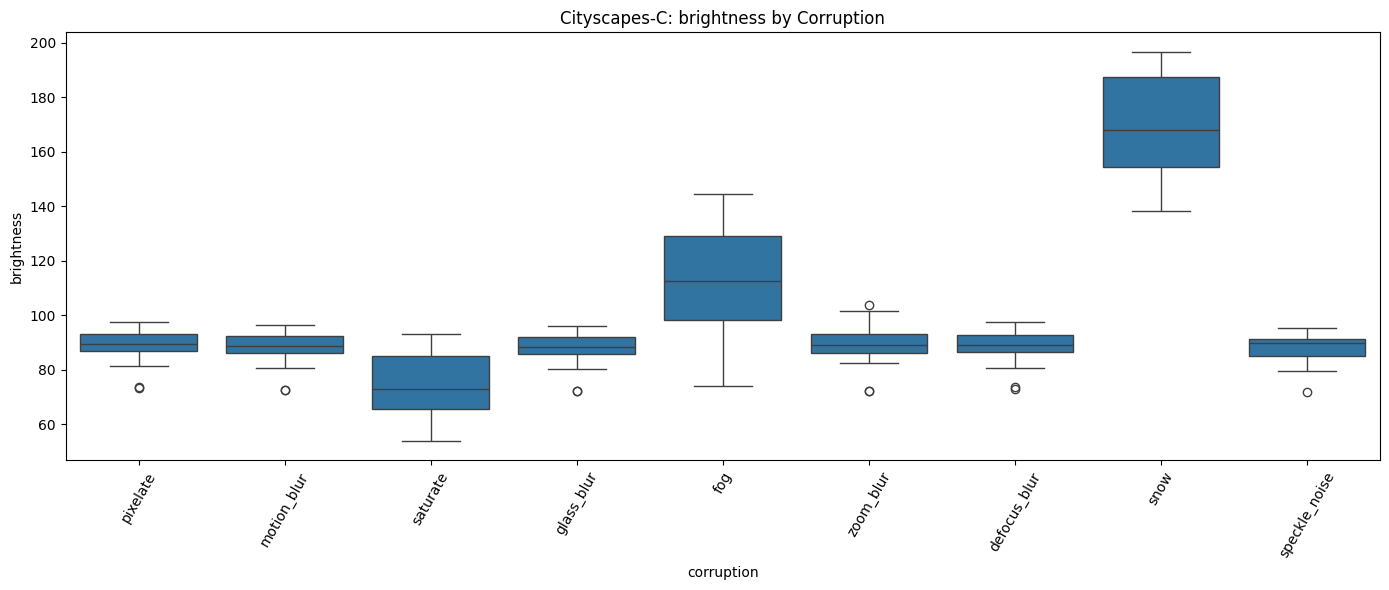

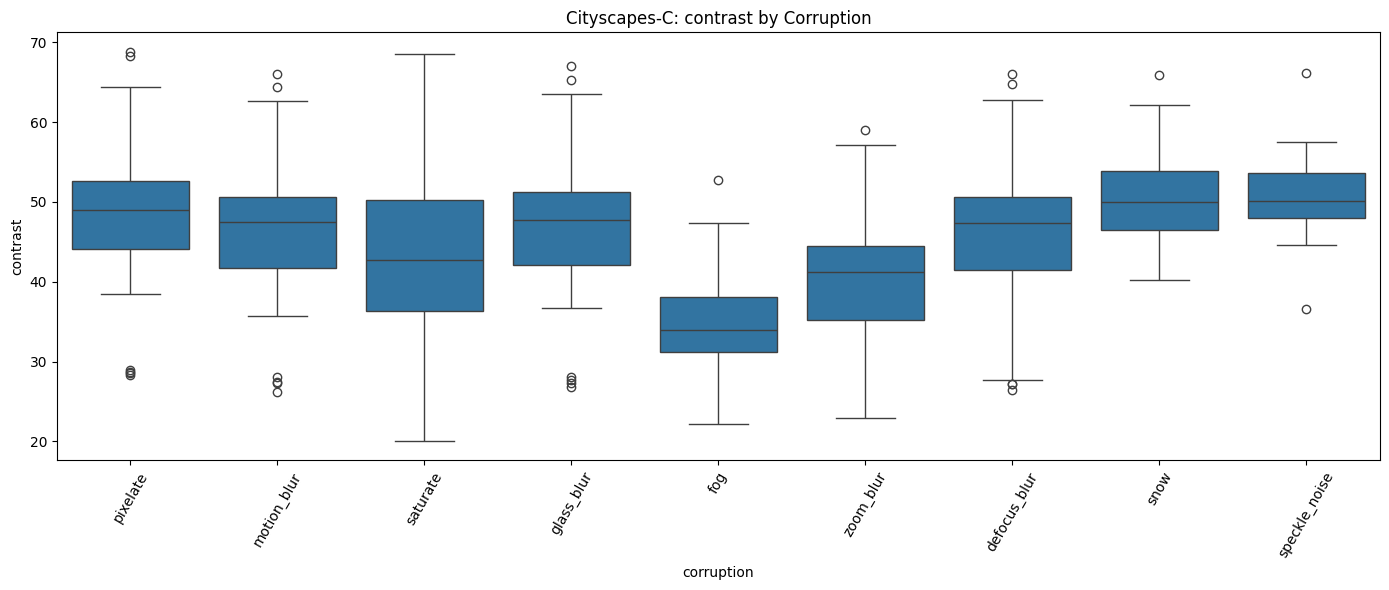

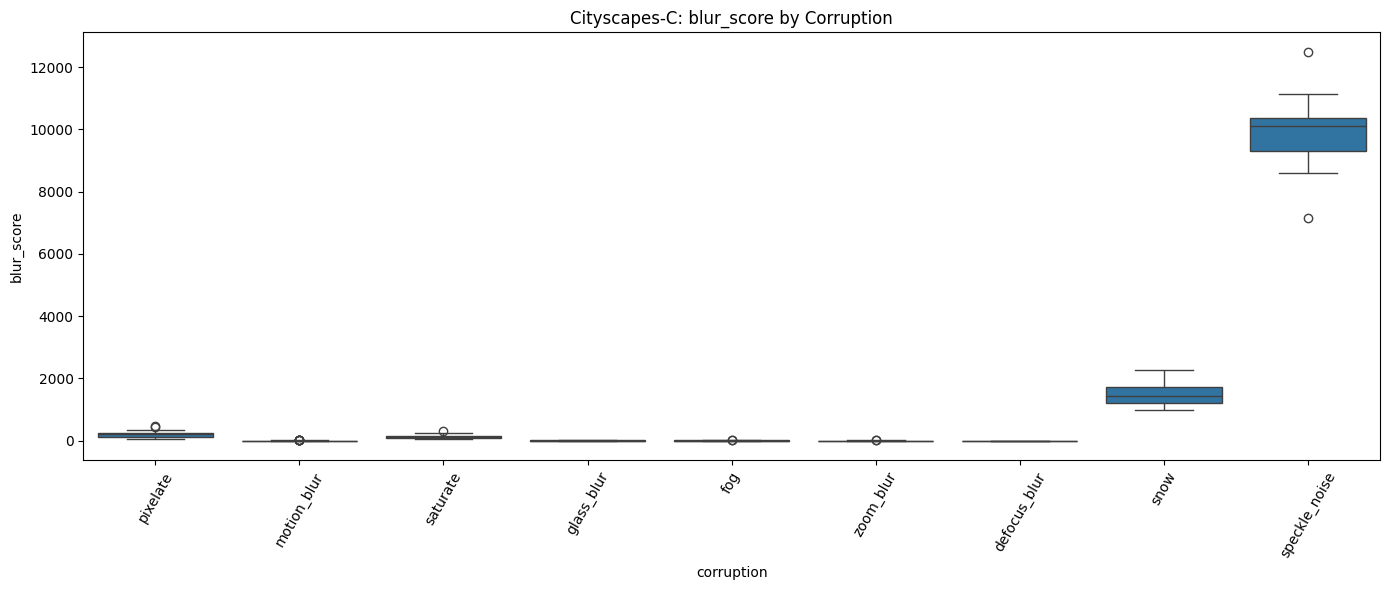

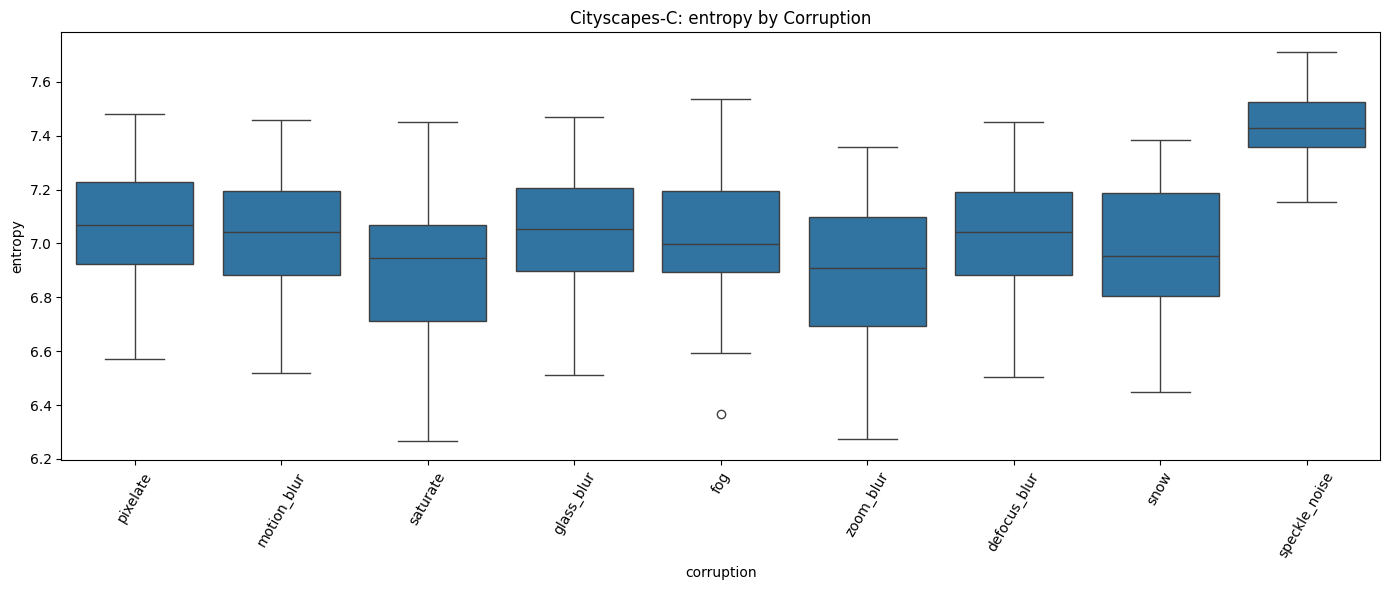

In [30]:
if len(cityc_df) > 0:

    quality_metrics = [
        "brightness",
        "contrast",
        "blur_score",
        "entropy"
    ]

    for metric in quality_metrics:

        plt.figure(figsize=(14, 6))

        sns.boxplot(
            data=cityc_df,
            x="corruption",
            y=metric
        )

        plt.title(
            f"Cityscapes-C: {metric} by Corruption"
        )

        plt.xticks(rotation=60)
        plt.tight_layout()

        plt.savefig(
            GRAPH_DIR / f"Cityscapes_C_{metric}_by_corruption.png",
            dpi=300
        )

        plt.show()

else:
    print("No data available for plotting.")

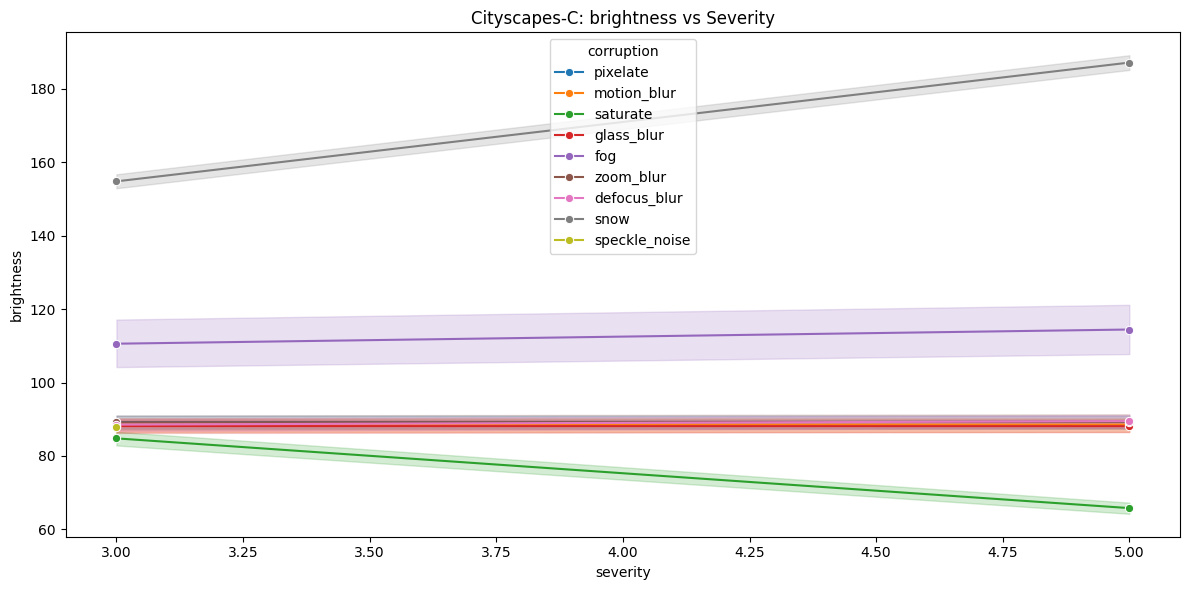

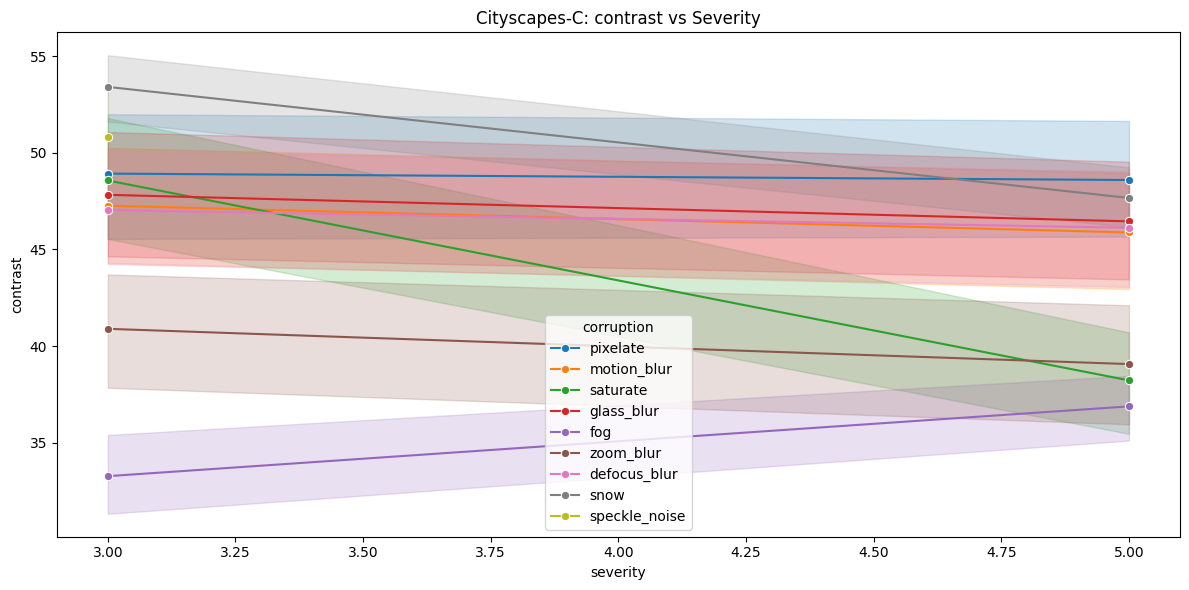

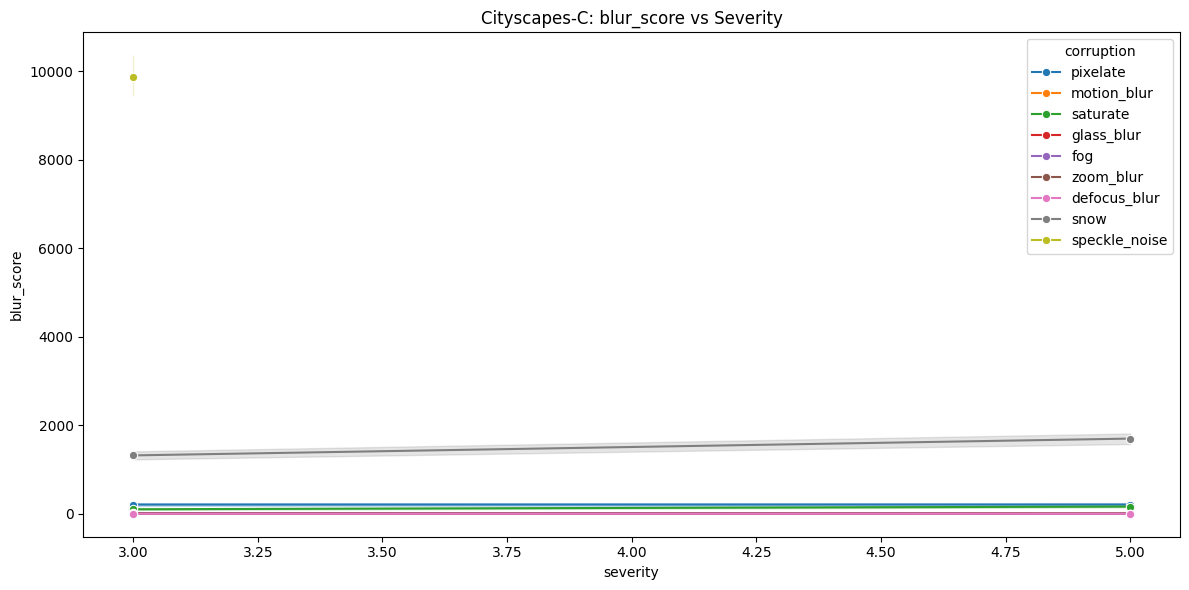

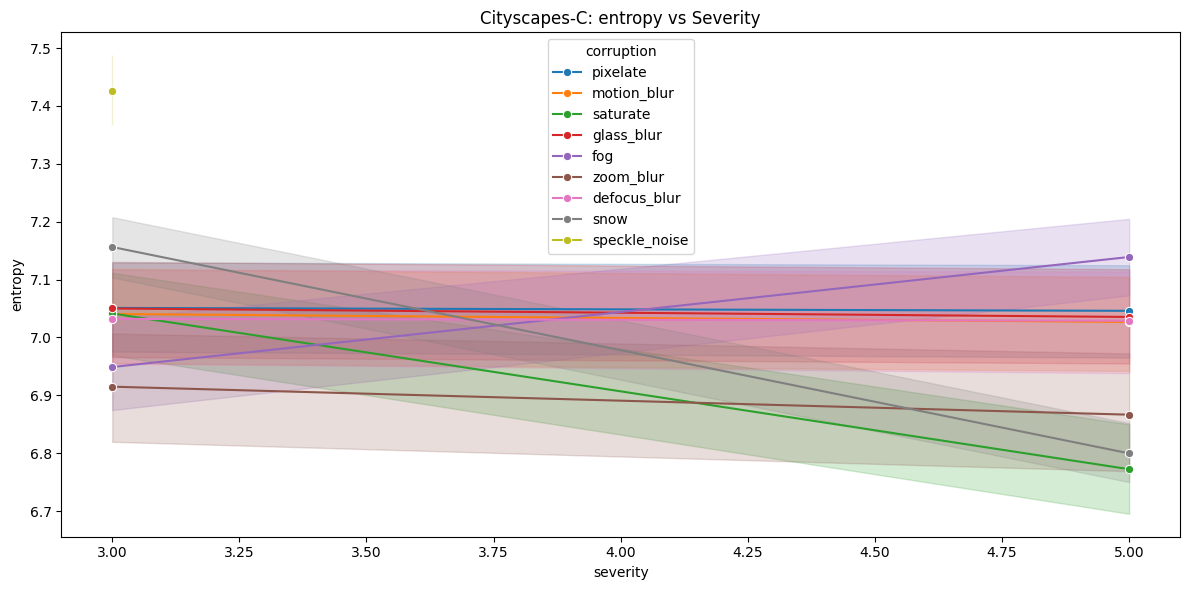

In [31]:
if len(cityc_df) > 0:

    severity_df = cityc_df[
        cityc_df["severity"].astype(str).str.isnumeric()
    ].copy()

    if not severity_df.empty:

        severity_df["severity"] = (
            severity_df["severity"].astype(int)
        )

        for metric in [
            "brightness",
            "contrast",
            "blur_score",
            "entropy"
        ]:

            plt.figure(figsize=(12, 6))

            sns.lineplot(
                data=severity_df,
                x="severity",
                y=metric,
                hue="corruption",
                marker="o"
            )

            plt.title(
                f"Cityscapes-C: {metric} vs Severity"
            )

            plt.tight_layout()

            plt.savefig(
                GRAPH_DIR / f"Cityscapes_C_{metric}_vs_severity.png",
                dpi=300
            )

            plt.show()

    else:
        print(
            "No numeric severity levels detected. "
            "Check the archive folder structure."
        )

In [32]:
if len(cityc_df) > 0:

    cityc_summary = cityc_df[
        [
            "brightness",
            "contrast",
            "blur_score",
            "entropy",
            "file_size_kb"
        ]
    ].describe().T

    display(cityc_summary)

    cityc_summary.to_csv(
        CSV_DIR / "Cityscapes_C_Descriptive_Statistics.csv"
    )

,count,mean,std,min,25%,50%,75%,max
brightness,500.0,99.856255,29.749090,53.859673,85.789732,90.401423,95.776253,196.652536
contrast,500.0,44.992599,9.316972,20.071492,38.451335,46.049632,51.044077,68.824191
blur_score,500.0,621.772372,1966.102203,1.031091,5.192011,10.556953,193.785929,12489.048727
entropy,500.0,7.014019,0.256054,6.267379,6.824890,7.022075,7.198443,7.711499
file_size_kb,500.0,1915.397158,1179.741011,272.469727,1256.860107,1555.450684,2580.192871,5742.109375


In [33]:
acdc_compare = acdc_df.copy()
cityc_compare = cityc_df.copy()

acdc_compare["dataset"] = "ACDC Fog"
cityc_compare["dataset"] = "Cityscapes-C"

common_columns = [
    "dataset",
    "brightness",
    "contrast",
    "blur_score",
    "entropy"
]

combined_df = pd.concat(
    [
        acdc_compare[common_columns],
        cityc_compare[common_columns]
    ],
    ignore_index=True
)

display(combined_df.head())

combined_df.to_csv(
    CSV_DIR / "ACDC_vs_CityscapesC_Comparison.csv",
    index=False
)

,dataset,brightness,contrast,blur_score,entropy
0,ACDC Fog,131.367083,62.247558,95.261711,7.278248
1,ACDC Fog,139.547808,62.714792,90.611107,7.297275
2,ACDC Fog,133.257877,60.498976,74.391833,7.039037
3,ACDC Fog,112.454598,66.503536,213.169715,7.483119
4,ACDC Fog,120.257494,77.053551,118.551596,7.516327


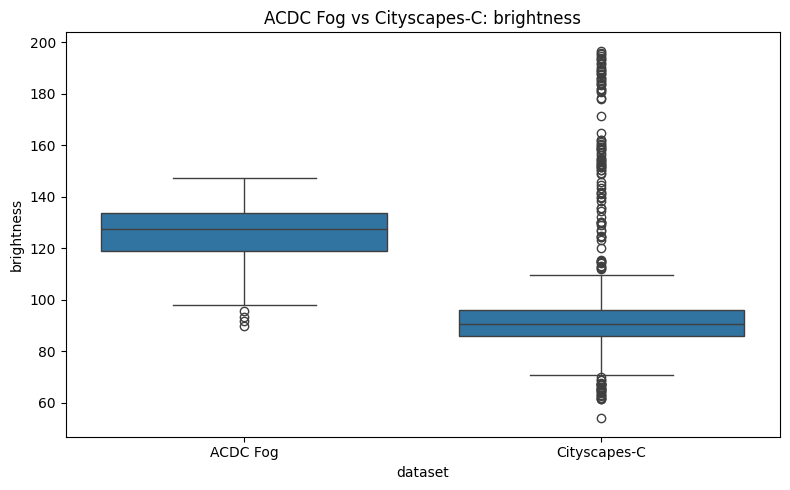

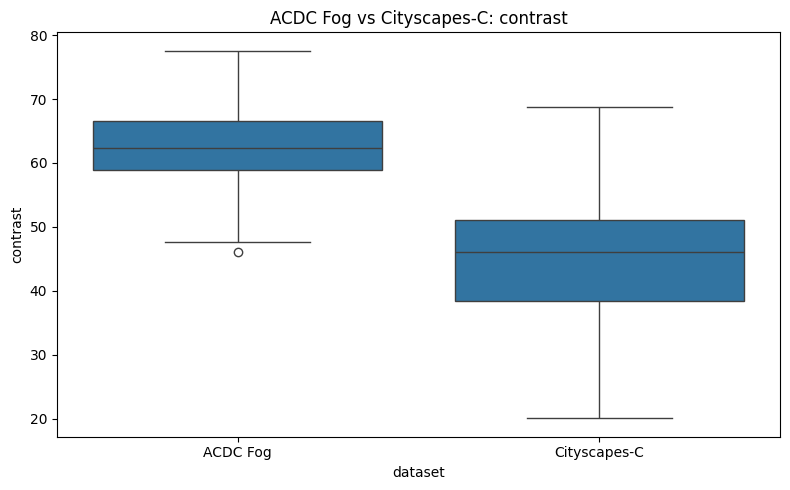

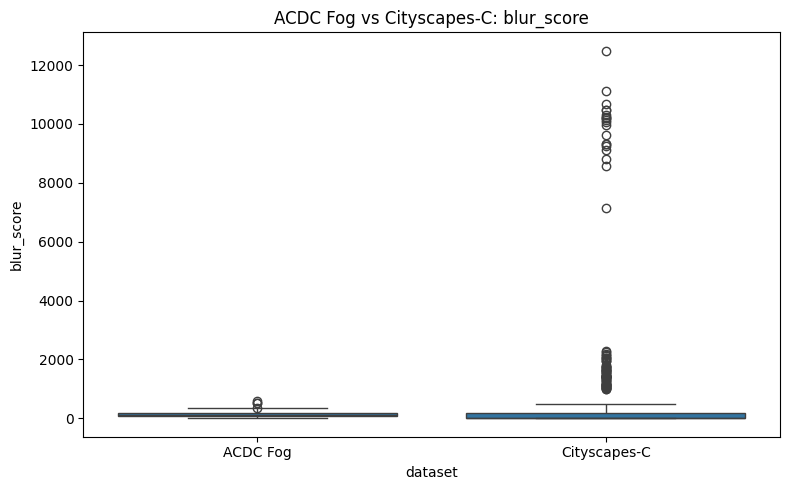

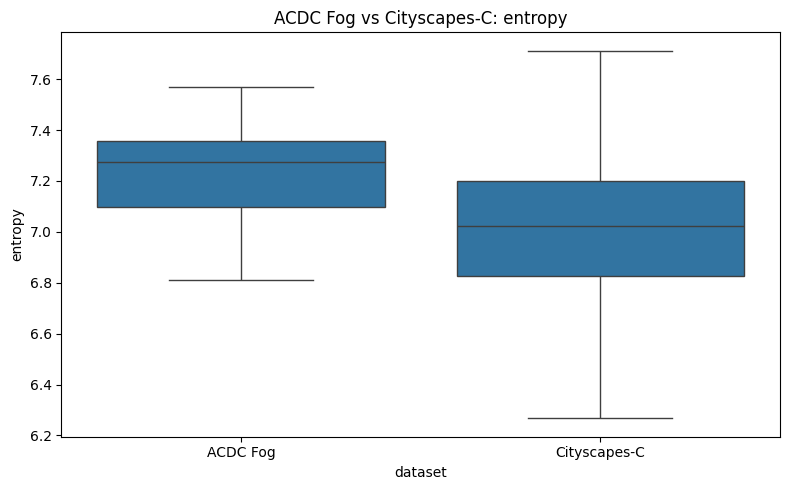

In [34]:
comparison_metrics = [
    "brightness",
    "contrast",
    "blur_score",
    "entropy"
]

for metric in comparison_metrics:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=combined_df,
        x="dataset",
        y=metric
    )

    plt.title(f"ACDC Fog vs Cityscapes-C: {metric}")

    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / f"Dataset_Comparison_{metric}.png",
        dpi=300
    )

    plt.show()

In [35]:
report = []

report.append("CITYSCAPES-RELATED DATASET EDA REPORT")
report.append("=" * 50)

report.append("\nACDC FOG")
report.append("-" * 30)

report.append(
    f"Images analysed: {len(acdc_df)}"
)

report.append(
    f"Masks analysed: {len(acdc_mask_df)}"
)

if len(acdc_df) > 0:

    report.append(
        f"Average brightness: {acdc_df['brightness'].mean():.2f}"
    )

    report.append(
        f"Average contrast: {acdc_df['contrast'].mean():.2f}"
    )

    report.append(
        f"Average blur score: {acdc_df['blur_score'].mean():.2f}"
    )

report.append("\nCITYSCAPES-C")
report.append("-" * 30)

report.append(
    f"Images analysed: {len(cityc_df)}"
)

if len(cityc_df) > 0:

    report.append(
        f"Average brightness: {cityc_df['brightness'].mean():.2f}"
    )

    report.append(
        f"Average contrast: {cityc_df['contrast'].mean():.2f}"
    )

    report.append(
        f"Average blur score: {cityc_df['blur_score'].mean():.2f}"
    )

    report.append(
        f"Corruption groups observed: {len(group_counts)}"
    )

report_text = "\n".join(report)

print(report_text)

with open(
    REPORT_DIR / "Dataset_EDA_Report.txt",
    "w"
) as file:

    file.write(report_text)

CITYSCAPES-RELATED DATASET EDA REPORT

ACDC FOG
------------------------------
Images analysed: 120
Masks analysed: 120
Average brightness: 125.24
Average contrast: 62.68
Average blur score: 140.54

CITYSCAPES-C
------------------------------
Images analysed: 500
Average brightness: 99.86
Average contrast: 44.99
Average blur score: 621.77
Corruption groups observed: 17


In [36]:
print("EDA output files:\n")

for folder in [CSV_DIR, GRAPH_DIR, REPORT_DIR]:

    print("\n", folder.name)

    for file in sorted(folder.iterdir()):
        print(" -", file.name)

EDA output files:


 csv
 - ACDC_Fog_Class_Pixel_Distribution.csv
 - ACDC_Fog_Descriptive_Statistics.csv
 - ACDC_vs_CityscapesC_Comparison.csv
 - Cityscapes_C_Descriptive_Statistics.csv
 - Cityscapes_C_Group_Summary.csv
 - Cityscapes_C_Image_Analysis.csv

 graphs
 - ACDC_Fog_Class_Distribution.png
 - ACDC_Fog_Quality_Distributions.png
 - ACDC_Fog_Sample_Images.png
 - Cityscapes_C_Sample_Images.png
 - Cityscapes_C_blur_score_by_corruption.png
 - Cityscapes_C_blur_score_vs_severity.png
 - Cityscapes_C_brightness_by_corruption.png
 - Cityscapes_C_brightness_vs_severity.png
 - Cityscapes_C_contrast_by_corruption.png
 - Cityscapes_C_contrast_vs_severity.png
 - Cityscapes_C_entropy_by_corruption.png
 - Cityscapes_C_entropy_vs_severity.png
 - Dataset_Comparison_blur_score.png
 - Dataset_Comparison_brightness.png
 - Dataset_Comparison_contrast.png
 - Dataset_Comparison_entropy.png

 reports
 - Dataset_EDA_Report.txt


In [37]:
# CELL 37 — Degradation experiment configuration

from skimage.metrics import structural_similarity

DEGRADATION_DIR = RESULT_DIR / "degradation_experiments"
DEGRADED_IMAGE_DIR = DEGRADATION_DIR / "images"
DEGRADATION_GRAPH_DIR = DEGRADATION_DIR / "graphs"
DEGRADATION_CSV_DIR = DEGRADATION_DIR / "csv"

for folder in [DEGRADED_IMAGE_DIR, DEGRADATION_GRAPH_DIR, DEGRADATION_CSV_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# EDA sample only. Increase this carefully; the full training corruption set
# should be generated as a separate, larger pipeline after EDA is approved.
MAX_DEGRADATION_IMAGES = 10
DEGRADATION_SEVERITIES = [1, 2, 3, 4, 5]
SAVE_DEGRADED_IMAGES = True
DEGRADED_JPEG_SAVE_QUALITY = 92

DEGRADATION_TYPES = [
    "gaussian_blur", "motion_blur", "defocus_blur",
    "gaussian_noise", "salt_pepper_noise", "speckle_noise",
    "jpeg_compression", "down_up_sampling",
    "brightness", "contrast", "gamma"
]

print("Degradation experiments configured.")
print("Degradation types:", len(DEGRADATION_TYPES))
print("Severity levels:", DEGRADATION_SEVERITIES)

Degradation experiments configured.
Degradation types: 11
Severity levels: [1, 2, 3, 4, 5]


In [38]:
# CELL 38 — Controlled degradation functions

_rng = np.random.default_rng(42)


def _clip_uint8(image):
    return np.clip(image, 0, 255).astype(np.uint8)


def apply_gaussian_blur(image, severity):
    kernels = [3, 5, 7, 9, 11]
    k = kernels[severity - 1]
    return cv2.GaussianBlur(image, (k, k), sigmaX=0)


def apply_motion_blur(image, severity):
    sizes = [3, 5, 7, 9, 13]
    k = sizes[severity - 1]
    kernel = np.zeros((k, k), dtype=np.float32)
    kernel[k // 2, :] = 1.0 / k
    return cv2.filter2D(image, -1, kernel)


def apply_defocus_blur(image, severity):
    radii = [1, 2, 3, 4, 5]
    radius = radii[severity - 1]
    size = 2 * radius + 1
    kernel = np.zeros((size, size), dtype=np.float32)
    yy, xx = np.ogrid[:size, :size]
    disk = (xx - radius) ** 2 + (yy - radius) ** 2 <= radius ** 2
    kernel[disk] = 1.0
    kernel /= kernel.sum()
    return cv2.filter2D(image, -1, kernel)


def apply_gaussian_noise(image, severity):
    std_levels = [5, 10, 15, 25, 35]
    noise = _rng.normal(0, std_levels[severity - 1], image.shape)
    return _clip_uint8(image.astype(np.float32) + noise)


def apply_salt_pepper_noise(image, severity):
    amounts = [0.005, 0.01, 0.02, 0.04, 0.06]
    amount = amounts[severity - 1]
    out = image.copy()
    h, w = image.shape[:2]
    n = int(amount * h * w)
    ys = _rng.integers(0, h, n)
    xs = _rng.integers(0, w, n)
    half = n // 2
    out[ys[:half], xs[:half]] = 0
    out[ys[half:], xs[half:]] = 255
    return out


def apply_speckle_noise(image, severity):
    std_levels = [0.03, 0.06, 0.10, 0.15, 0.20]
    noise = _rng.normal(0, std_levels[severity - 1], image.shape)
    out = image.astype(np.float32) * (1.0 + noise)
    return _clip_uint8(out)


def apply_jpeg_compression(image, severity):
    qualities = [80, 60, 40, 20, 10]
    quality = qualities[severity - 1]
    ok, encoded = cv2.imencode(
        ".jpg", cv2.cvtColor(image, cv2.COLOR_RGB2BGR),
        [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    )
    if not ok:
        raise RuntimeError("JPEG encoding failed")
    decoded = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    return cv2.cvtColor(decoded, cv2.COLOR_BGR2RGB)


def apply_down_up_sampling(image, severity):
    scale_factors = [0.75, 0.50, 0.35, 0.25, 0.15]
    scale = scale_factors[severity - 1]
    h, w = image.shape[:2]
    small_w = max(1, int(w * scale))
    small_h = max(1, int(h * scale))
    small = cv2.resize(image, (small_w, small_h), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)


def apply_brightness(image, severity):
    offsets = [-10, -20, -30, -40, -50]
    return _clip_uint8(image.astype(np.float32) + offsets[severity - 1])


def apply_contrast(image, severity):
    factors = [0.90, 0.80, 0.70, 0.60, 0.50]
    factor = factors[severity - 1]
    mean = image.mean(axis=(0, 1), keepdims=True)
    return _clip_uint8((image.astype(np.float32) - mean) * factor + mean)


def apply_gamma(image, severity):
    gamma_values = [0.90, 0.80, 0.70, 0.60, 0.50]
    gamma = gamma_values[severity - 1]
    lut = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype("uint8")
    return cv2.LUT(image, lut)


DEGRADATION_FUNCTIONS = {
    "gaussian_blur": apply_gaussian_blur,
    "motion_blur": apply_motion_blur,
    "defocus_blur": apply_defocus_blur,
    "gaussian_noise": apply_gaussian_noise,
    "salt_pepper_noise": apply_salt_pepper_noise,
    "speckle_noise": apply_speckle_noise,
    "jpeg_compression": apply_jpeg_compression,
    "down_up_sampling": apply_down_up_sampling,
    "brightness": apply_brightness,
    "contrast": apply_contrast,
    "gamma": apply_gamma,
}

print("All degradation functions are ready.")

All degradation functions are ready.


In [39]:
# CELL 39 — Select source images and calculate image-quality metrics


def calculate_psnr(reference, distorted):
    ref = reference.astype(np.float32)
    dist = distorted.astype(np.float32)
    mse = np.mean((ref - dist) ** 2)
    if mse == 0:
        return float("inf")
    return float(20 * np.log10(255.0 / np.sqrt(mse)))


def calculate_ssim(reference, distorted):
    return float(structural_similarity(
        reference, distorted, channel_axis=2, data_range=255
    ))


def calculate_degradation_metrics(reference, distorted):
    gray = cv2.cvtColor(distorted, cv2.COLOR_RGB2GRAY)
    return {
        "psnr_db": calculate_psnr(reference, distorted),
        "ssim": calculate_ssim(reference, distorted),
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
        "laplacian_variance": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "entropy": float(calculate_entropy(gray)),
    }

# Reuse the already selected ACDC sample; do not download a second copy.
if "acdc_sample" not in globals() or len(acdc_sample) == 0:
    raise ValueError("acdc_sample is empty. Run the original ACDC EDA cells first.")

_degradation_sources = acdc_sample[:min(MAX_DEGRADATION_IMAGES, len(acdc_sample))]
print("Source images selected for degradation:", len(_degradation_sources))
print("Expected image variants:", len(_degradation_sources) * len(DEGRADATION_TYPES) * len(DEGRADATION_SEVERITIES))

Source images selected for degradation: 10
Expected image variants: 550


In [40]:
# CELL 40 — Generate degraded images and build the results table

_degradation_records = []
_degradation_previews = {}

for source_index, item in enumerate(tqdm(_degradation_sources, desc="Source images"), start=1):
    try:
        source_bytes = acdc_rgb_zip.read(item["image_path"])
        source_pil = Image.open(io.BytesIO(source_bytes)).convert("RGB")
        clean = np.array(source_pil, dtype=np.uint8)
        source_name = Path(item["image_path"]).stem

        for degradation_name, degradation_function in DEGRADATION_FUNCTIONS.items():
            for severity in DEGRADATION_SEVERITIES:
                degraded = degradation_function(clean.copy(), severity)
                metrics_result = calculate_degradation_metrics(clean, degraded)

                record = {
                    "source_filename": Path(item["image_path"]).name,
                    "source_key": item.get("key", source_name),
                    "split": item.get("split", "unknown"),
                    "degradation": degradation_name,
                    "severity": severity,
                    "width": int(degraded.shape[1]),
                    "height": int(degraded.shape[0]),
                    **metrics_result,
                }
                _degradation_records.append(record)

                # Keep one representative visual comparison per degradation.
                if severity in [1, 3, 5] and degradation_name not in _degradation_previews:
                    _degradation_previews[degradation_name] = {
                        "clean": clean.copy(),
                        "degraded": degraded.copy(),
                        "severity": severity,
                        "filename": Path(item["image_path"]).name,
                    }

                if SAVE_DEGRADED_IMAGES:
                    output_folder = DEGRADED_IMAGE_DIR / degradation_name / f"severity_{severity}"
                    output_folder.mkdir(parents=True, exist_ok=True)
                    output_path = output_folder / f"{source_index:03d}_{source_name}.jpg"
                    bgr = cv2.cvtColor(degraded, cv2.COLOR_RGB2BGR)
                    cv2.imwrite(
                        str(output_path), bgr,
                        [int(cv2.IMWRITE_JPEG_QUALITY), DEGRADED_JPEG_SAVE_QUALITY]
                    )

        del source_bytes, source_pil, clean

    except Exception as e:
        print("Could not process source:", item.get("image_path", "unknown"), "|", str(e))


degradation_df = pd.DataFrame(_degradation_records)
print("\nDegradation experiment completed.")
print("Rows generated:", len(degradation_df))
display(degradation_df.head())

Source images:   0%|          | 0/10 [00:00<?, ?it/s]


Degradation experiment completed.
Rows generated: 550


,source_filename,source_key,split,degradation,severity,width,height,psnr_db,ssim,brightness,contrast,laplacian_variance,entropy
0,GOPR0477_frame_000756_rgb_anon.png,GOPR0477_frame_000756,train,gaussian_blur,1,1920,1080,41.253555,0.982926,131.401117,62.069843,22.838547,7.271269
1,GOPR0477_frame_000756_rgb_anon.png,GOPR0477_frame_000756,train,gaussian_blur,2,1920,1080,38.001900,0.966816,131.373565,61.989064,11.162116,7.269619
2,GOPR0477_frame_000756_rgb_anon.png,GOPR0477_frame_000756,train,gaussian_blur,3,1920,1080,35.487949,0.944373,131.372269,61.890572,5.067416,7.267806
3,GOPR0477_frame_000756_rgb_anon.png,GOPR0477_frame_000756,train,gaussian_blur,4,1920,1080,34.298065,0.929055,131.372556,61.826643,3.262068,7.266752
4,GOPR0477_frame_000756_rgb_anon.png,GOPR0477_frame_000756,train,gaussian_blur,5,1920,1080,33.377102,0.914668,131.373621,61.769675,2.289041,7.265864


In [41]:
# CELL 41 — Save degradation metrics and summary tables

if degradation_df.empty:
    raise ValueError("No degradation records were generated. Check the source images and archive access.")

metrics_csv_path = DEGRADATION_CSV_DIR / "ACDC_Degradation_Quality_Metrics.csv"
degradation_df.to_csv(metrics_csv_path, index=False)

severity_summary = (
    degradation_df
    .groupby(["degradation", "severity"])
    .agg(
        image_count=("source_filename", "count"),
        mean_psnr_db=("psnr_db", "mean"),
        mean_ssim=("ssim", "mean"),
        mean_brightness=("brightness", "mean"),
        mean_contrast=("contrast", "mean"),
        mean_laplacian_variance=("laplacian_variance", "mean"),
        mean_entropy=("entropy", "mean"),
    )
    .reset_index()
)

summary_csv_path = DEGRADATION_CSV_DIR / "ACDC_Degradation_Severity_Summary.csv"
severity_summary.to_csv(summary_csv_path, index=False)

display(severity_summary.head(15))
print("Saved:", metrics_csv_path)
print("Saved:", summary_csv_path)

,degradation,severity,image_count,mean_psnr_db,mean_ssim,mean_brightness,mean_contrast,mean_laplacian_variance,mean_entropy
0,brightness,1,10,28.131945,0.982330,114.825026,66.291493,173.333715,7.316158
1,brightness,2,10,22.138655,0.926024,104.902125,66.184800,172.302354,7.256395
2,brightness,3,10,18.689799,0.852561,95.241471,65.746363,169.461154,7.124239
3,brightness,4,10,16.285571,0.768916,85.905000,64.931562,164.732983,6.942601
4,brightness,5,10,14.466827,0.681225,76.999461,63.661872,158.397325,6.689250
5,contrast,1,10,31.580382,0.992386,124.327033,59.681372,141.204775,7.148210
6,contrast,2,10,25.583071,0.975454,124.324721,53.060535,111.882519,6.969807
7,contrast,3,10,22.065088,0.952478,124.300408,46.400968,85.951328,6.776356
8,contrast,4,10,19.567899,0.924260,124.301812,39.758808,63.408447,6.553588
9,contrast,5,10,17.630489,0.891017,124.295217,33.119972,44.187697,6.315332


Saved: /content/drive/MyDrive/Cityscapes_EDA/results/degradation_experiments/csv/ACDC_Degradation_Quality_Metrics.csv
Saved: /content/drive/MyDrive/Cityscapes_EDA/results/degradation_experiments/csv/ACDC_Degradation_Severity_Summary.csv


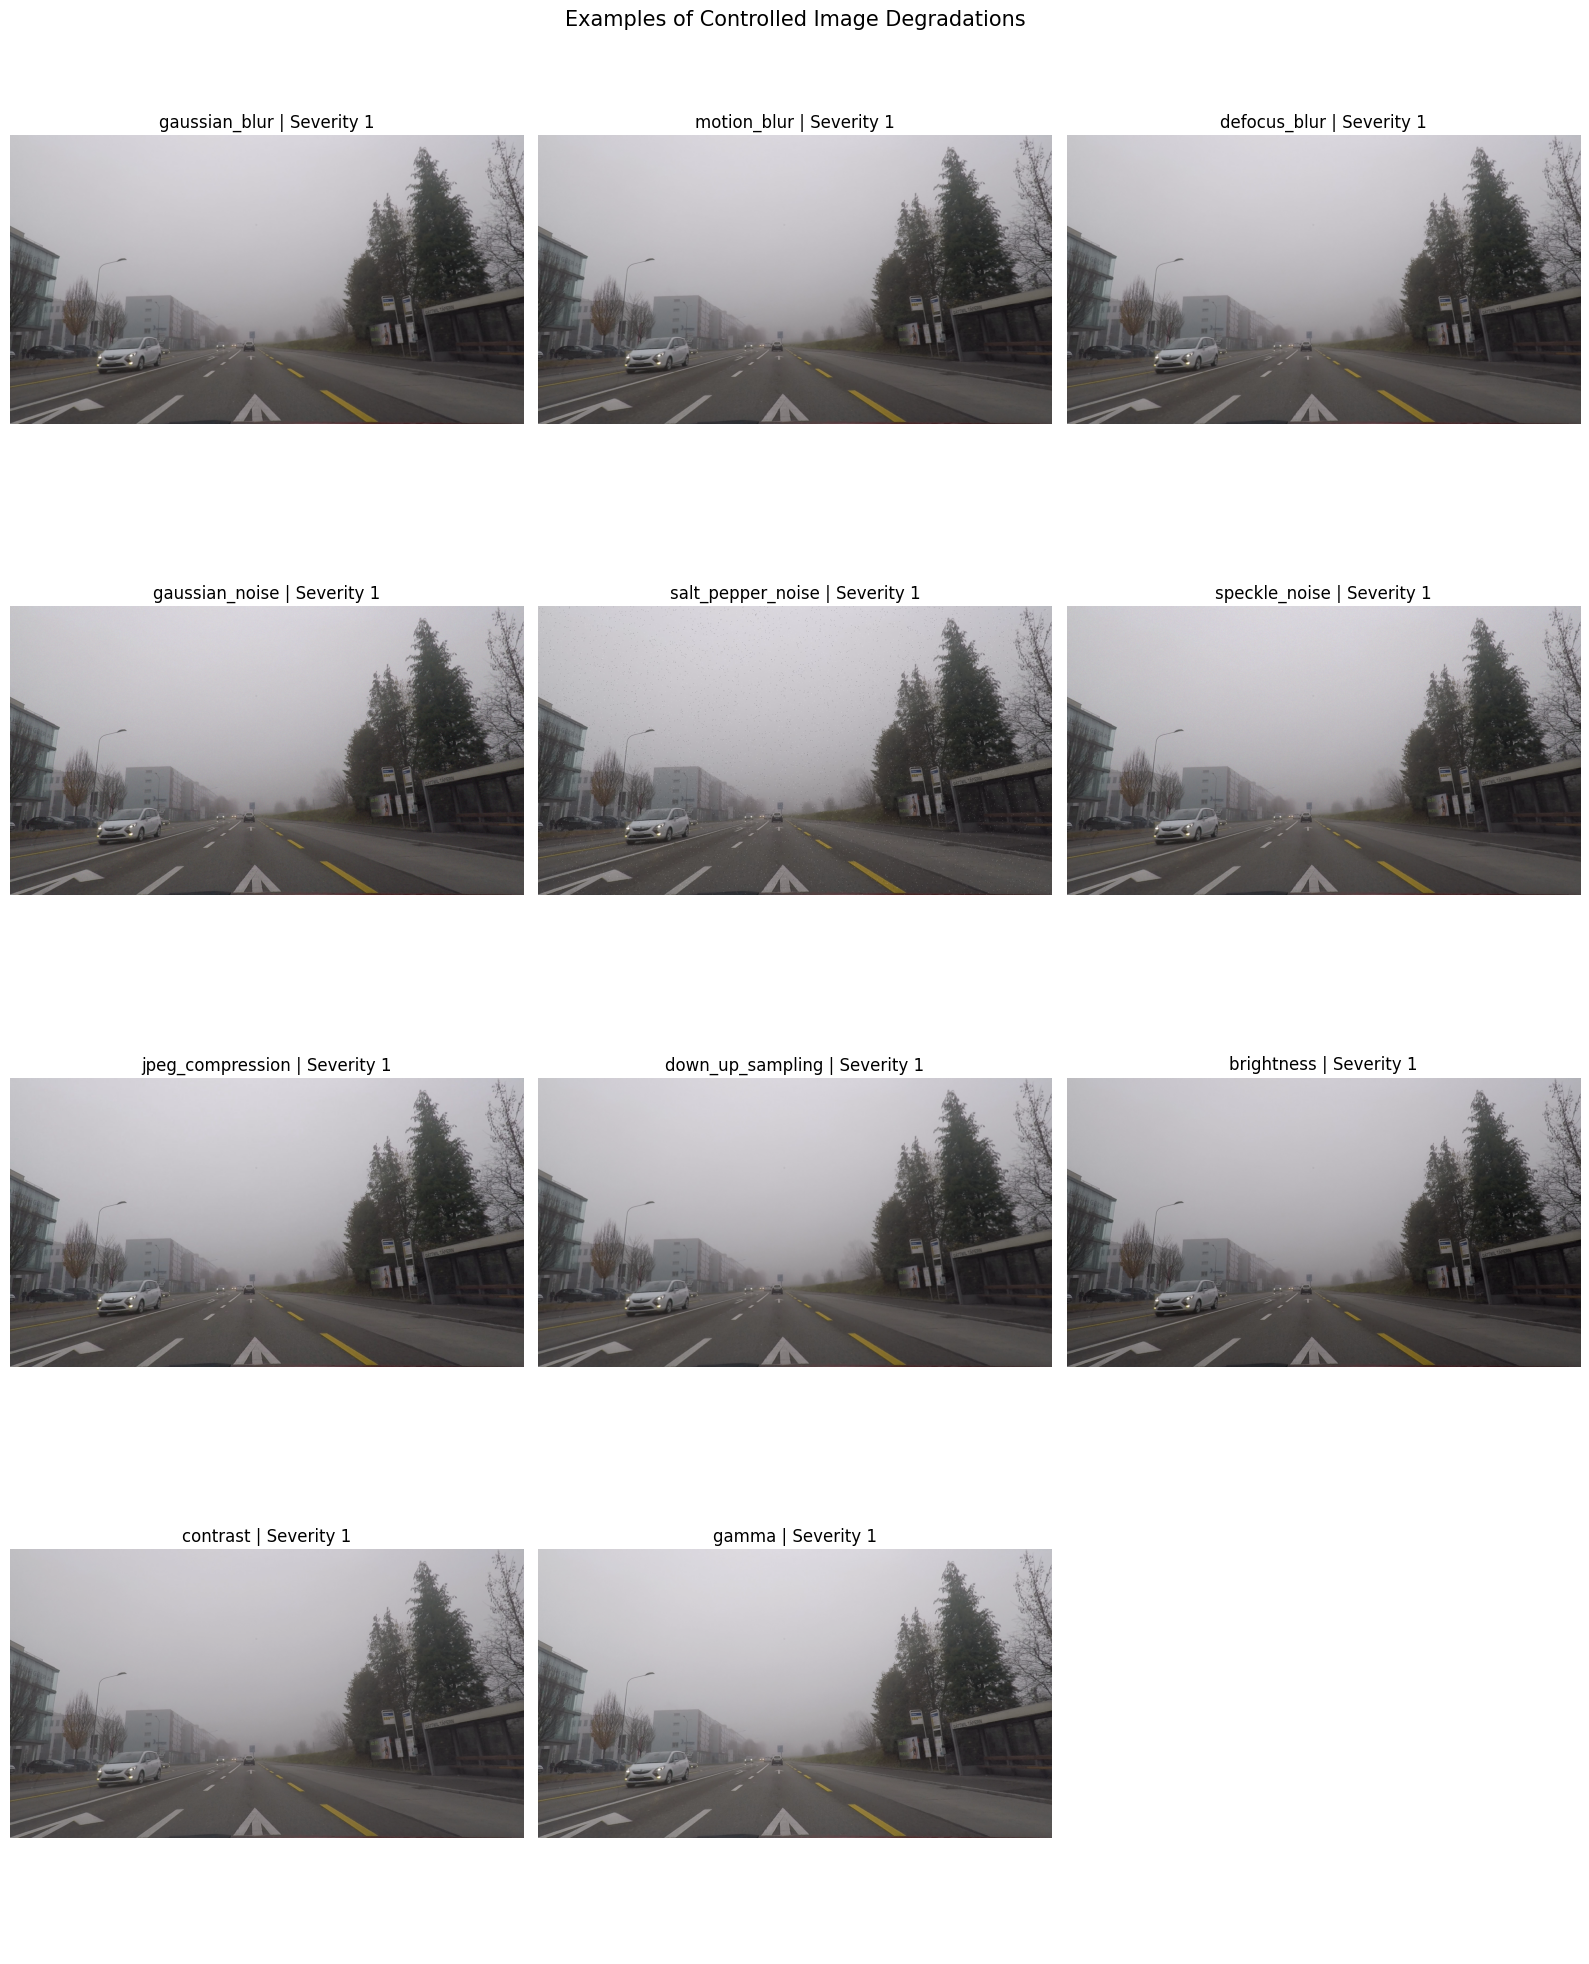

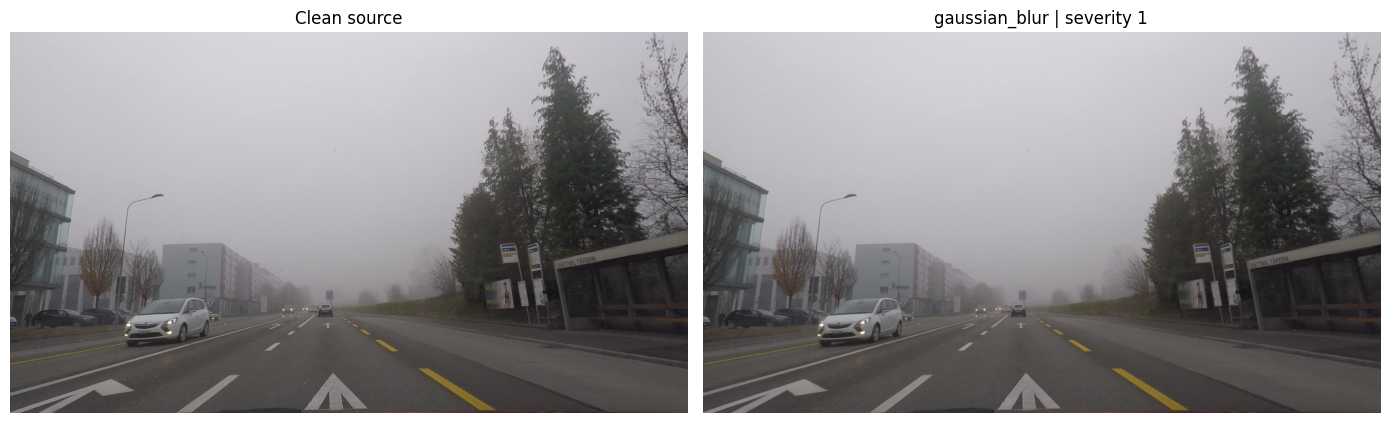

In [42]:
# CELL 42 — Visual comparison: clean image vs degraded versions

if _degradation_previews:
    names = list(_degradation_previews.keys())
    columns = 3
    rows = int(np.ceil(len(names) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, name in zip(axes, names):
        preview = _degradation_previews[name]
        ax.imshow(preview["degraded"])
        ax.set_title(f"{name} | Severity {preview['severity']}")
        ax.axis("off")

    for ax in axes[len(names):]:
        ax.axis("off")

    plt.suptitle("Examples of Controlled Image Degradations", fontsize=15)
    plt.tight_layout()
    plt.savefig(DEGRADATION_GRAPH_DIR / "Degradation_Examples.png", dpi=250)
    plt.show()

    # A direct clean/degraded pair for a quick visual sanity check.
    first_name = names[0]
    first_preview = _degradation_previews[first_name]
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(first_preview["clean"])
    axes[0].set_title("Clean source")
    axes[1].imshow(first_preview["degraded"])
    axes[1].set_title(f"{first_name} | severity {first_preview['severity']}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(DEGRADATION_GRAPH_DIR / "Clean_vs_Degraded_Example.png", dpi=250)
    plt.show()

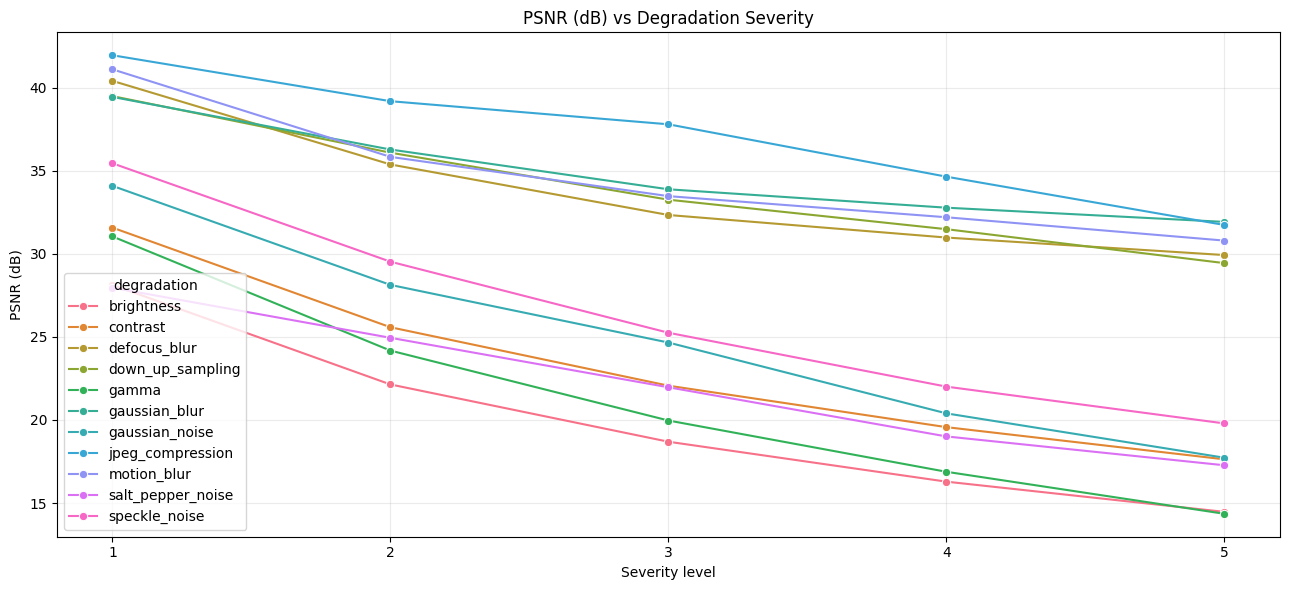

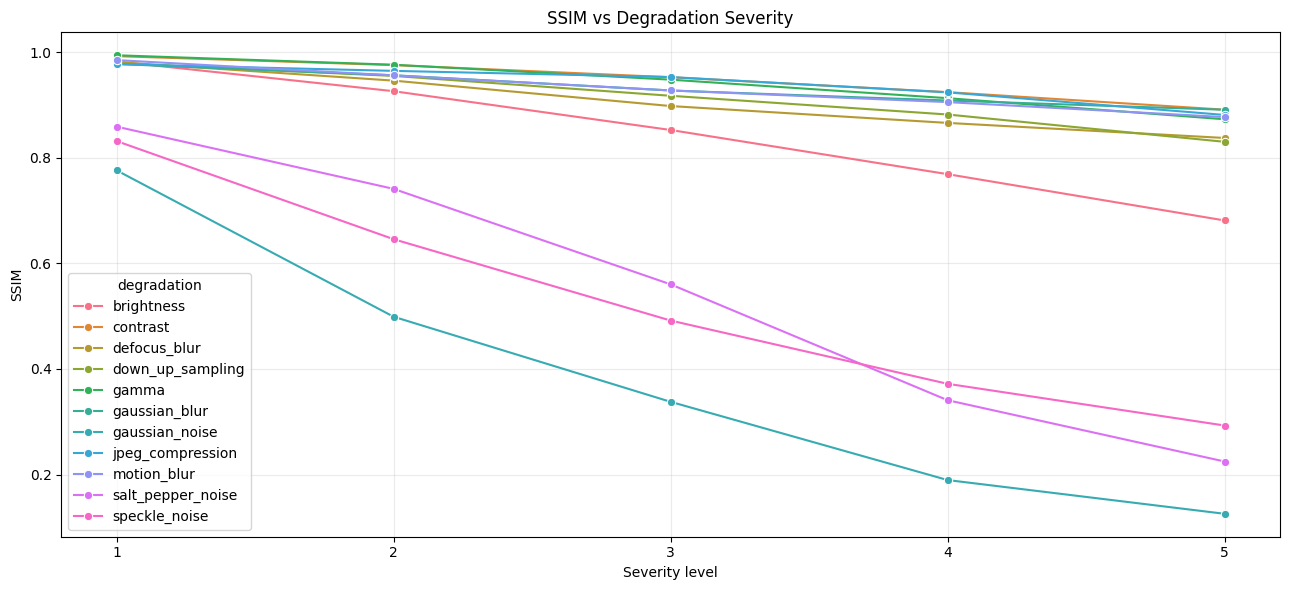

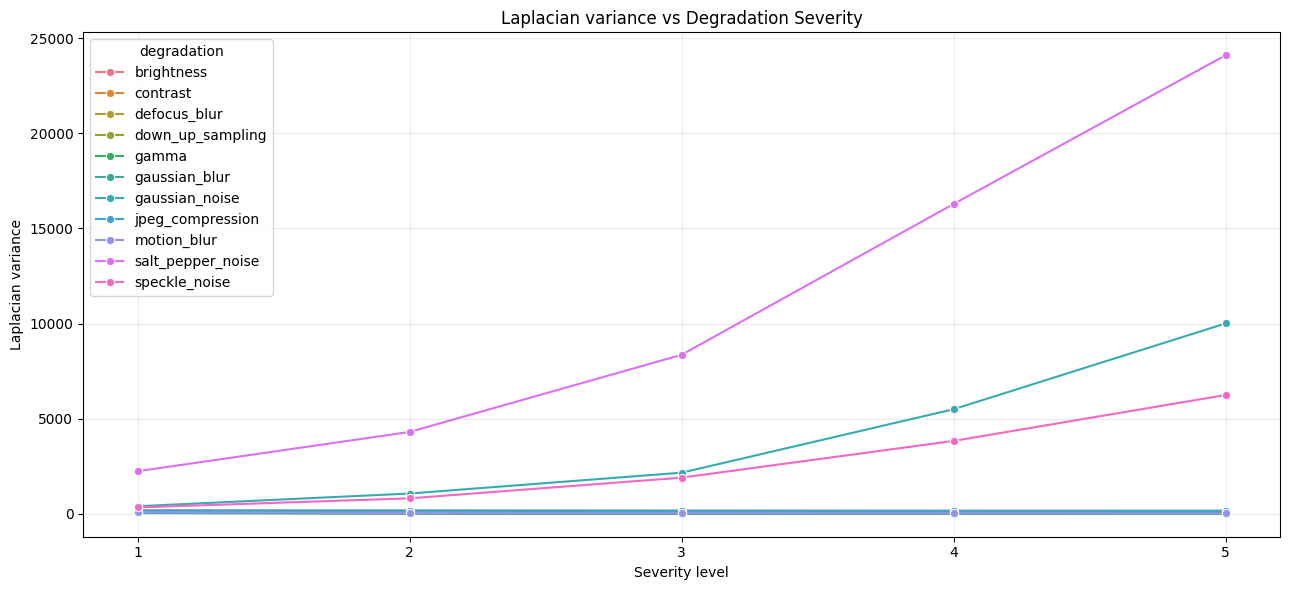

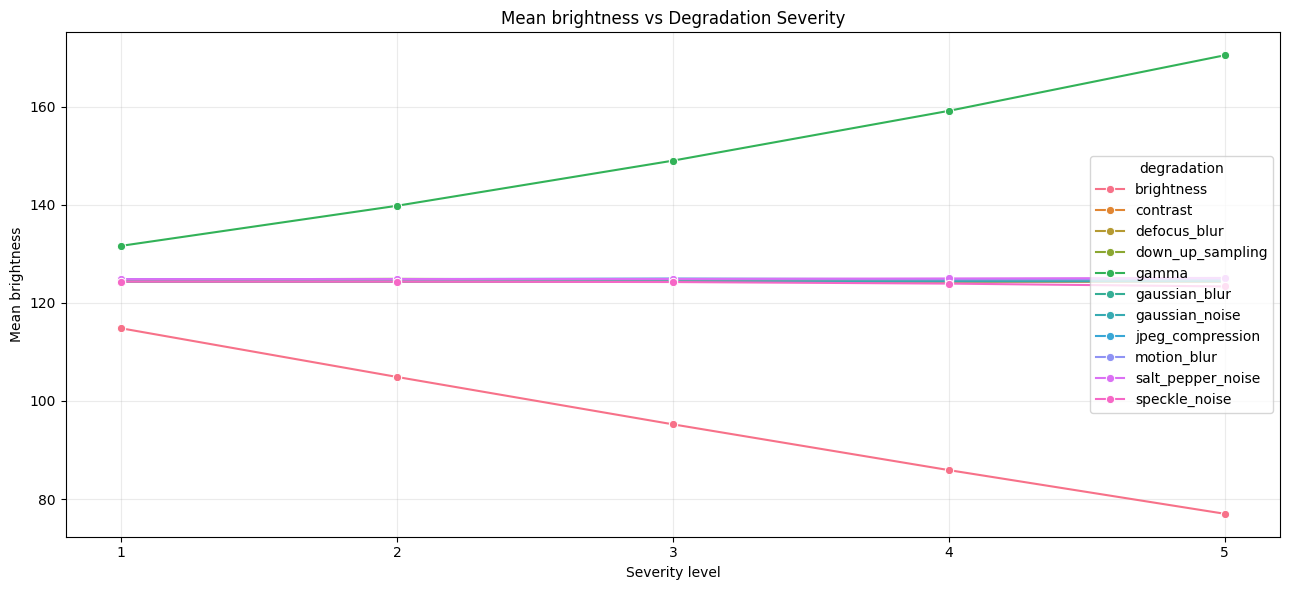

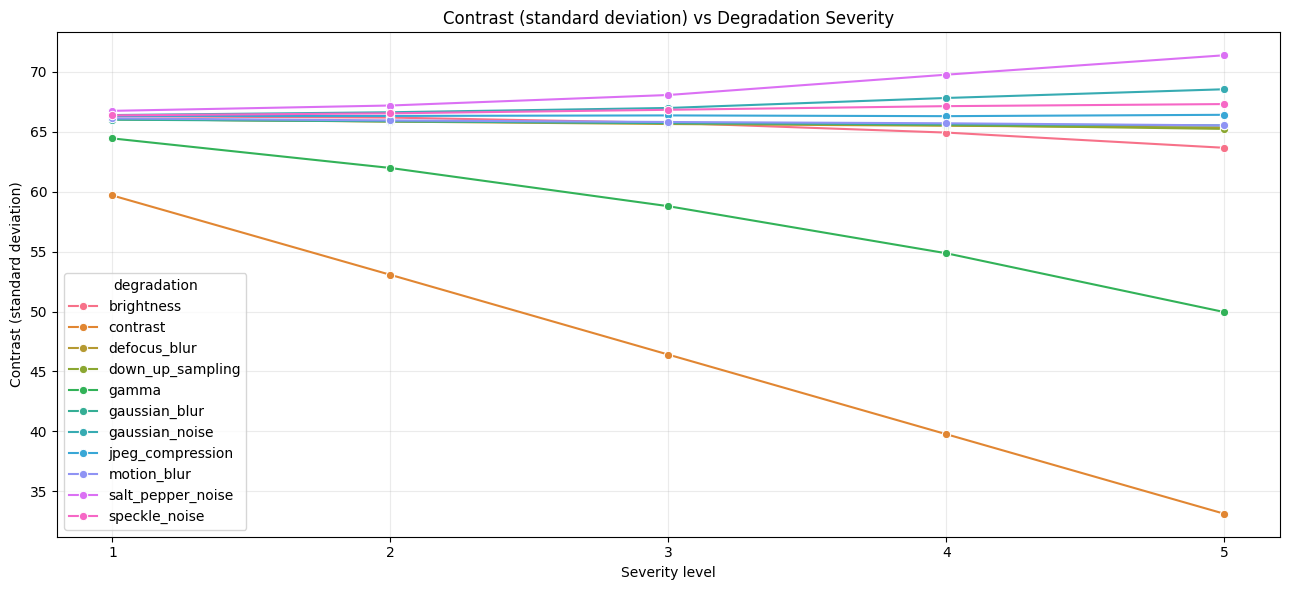

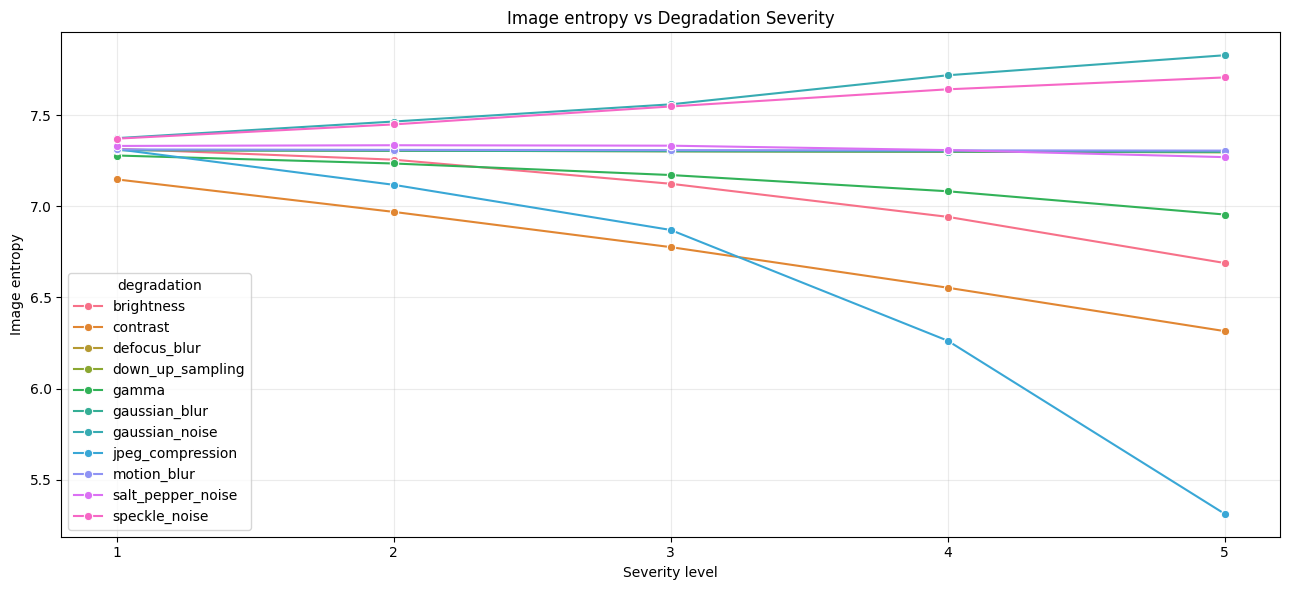

In [43]:
# CELL 43 — Quality metrics across degradation severity levels

plot_metrics = [
    ("psnr_db", "PSNR (dB)"),
    ("ssim", "SSIM"),
    ("laplacian_variance", "Laplacian variance"),
    ("brightness", "Mean brightness"),
    ("contrast", "Contrast (standard deviation)"),
    ("entropy", "Image entropy"),
]

for metric, label in plot_metrics:
    plt.figure(figsize=(13, 6))
    sns.lineplot(
        data=severity_summary,
        x="severity",
        y=f"mean_{metric}" if f"mean_{metric}" in severity_summary.columns else metric,
        hue="degradation",
        marker="o"
    )
    plt.title(f"{label} vs Degradation Severity")
    plt.xlabel("Severity level")
    plt.ylabel(label)
    plt.xticks(DEGRADATION_SEVERITIES)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    safe_metric = metric.replace("/", "_")
    plt.savefig(DEGRADATION_GRAPH_DIR / f"{safe_metric}_vs_severity.png", dpi=250)
    plt.show()

In [44]:
# CELL 44 — Compare degradation families and export final experiment report

family_map = {
    "gaussian_blur": "Blur", "motion_blur": "Blur", "defocus_blur": "Blur",
    "gaussian_noise": "Noise", "salt_pepper_noise": "Noise", "speckle_noise": "Noise",
    "jpeg_compression": "Compression", "down_up_sampling": "Resolution",
    "brightness": "Lighting", "contrast": "Lighting", "gamma": "Lighting",
}

degradation_df["degradation_family"] = degradation_df["degradation"].map(family_map)
family_summary = (
    degradation_df
    .groupby(["degradation_family", "degradation", "severity"])
    [["psnr_db", "ssim", "brightness", "contrast", "laplacian_variance", "entropy"]]
    .mean()
    .reset_index()
)
family_summary.to_csv(DEGRADATION_CSV_DIR / "Degradation_Family_Summary.csv", index=False)

report_lines = [
    "CONTROLLED IMAGE DEGRADATION EDA REPORT",
    "=" * 55,
    f"Source images used: {len(_degradation_sources)}",
    f"Degradation types: {len(DEGRADATION_TYPES)}",
    f"Severity levels: {DEGRADATION_SEVERITIES}",
    f"Total degraded variants measured: {len(degradation_df)}",
    f"Degraded images saved: {SAVE_DEGRADED_IMAGES}",
    "",
    "Mean quality metrics by degradation and severity:",
    severity_summary.to_string(index=False),
]
report_path = DEGRADATION_DIR / "Controlled_Degradation_EDA_Report.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("Degradation EDA outputs saved under:", DEGRADATION_DIR)
print("\nOutput folders:")
for folder in [DEGRADED_IMAGE_DIR, DEGRADATION_CSV_DIR, DEGRADATION_GRAPH_DIR]:
    print("-", folder)

Degradation EDA outputs saved under: /content/drive/MyDrive/Cityscapes_EDA/results/degradation_experiments

Output folders:
- /content/drive/MyDrive/Cityscapes_EDA/results/degradation_experiments/images
- /content/drive/MyDrive/Cityscapes_EDA/results/degradation_experiments/csv
- /content/drive/MyDrive/Cityscapes_EDA/results/degradation_experiments/graphs
